#Initial

In [10]:
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

try:
    from numba import njit
except ImportError as exc:
    raise ImportError("This notebook requires numba. Install it with: pip install numba") from exc

FIGDIR = Path("figures_chapter1")
FIGDIR.mkdir(exist_ok=True)

# Fixed AP-model parameters
CM = 1.0          # microF / cm^2
GKB = 0.15200     # mS / cm^2
GNAB = 0.01600    # mS / cm^2
CK = 0.12500      # mS / cm^2 / mV^2
CNA = 0.00550     # mS / cm^2 / mV
VK = -82.0        # mV
VNA = 45.0        # mV
V0 = -70.0        # mV
VTH = -60.0       # mV
VMAX = -18.0      # mV
TAU_K = 1.3       # ms
TAU_M = 0.19903   # ms
TAU_H = 2.75768   # ms
DT = 0.001        # ms
SPIKE_THRESHOLD = 0.0  # mV

# Tissue parameters used in the original examples
SIGMA = 1.0       # mS / cm
CHI = 1000.0      # cm^-1
D = SIGMA / (CHI * CM)  # cm^2 / ms

print(f"D = {D:.4g} cm^2/ms")
print(f"Resting sodium availability h(V0) = {max(VMAX - max(V0, VTH), 0.0):.1f}")

D = 0.001 cm^2/ms
Resting sodium availability h(V0) = 42.0


# Fig. 2.2: Action potential propagation


Gt = 0.1
  Neuron 1 activation time (crossing -60.0 mV): 4.534569591075245
  Neuron 4 activation time (crossing -60.0 mV): 9.502037407052438
  Neuron 7 activation time (crossing -60.0 mV): 14.5672594148999
  Neuron 10 activation time (crossing -60.0 mV): 19.56507092071095
  Approx. speed: 0.599 cells/ms (using neuron 1→10 activation delay)

Gt = 0.4
  Neuron 1 activation time (crossing -60.0 mV): 4.580087172981405
  Neuron 4 activation time (crossing -60.0 mV): 6.821910445921225
  Neuron 7 activation time (crossing -60.0 mV): 8.949300669059772
  Neuron 10 activation time (crossing -60.0 mV): 11.049661062695703
  Approx. speed: 1.391 cells/ms (using neuron 1→10 activation delay)


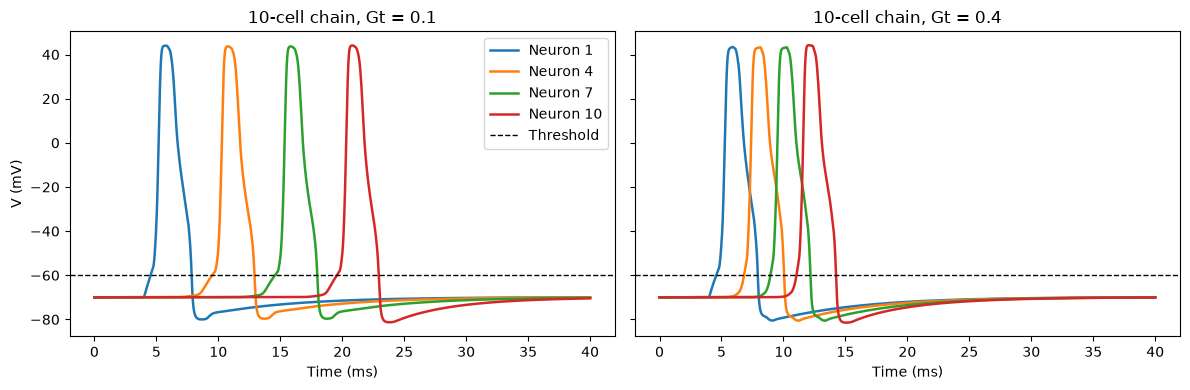

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ============================
# Parameters (from your code)
# ============================
T_max = 40.0          # ms (enough to see propagation to cell 10)
dt    = 0.001         # ms
Cm    = 1.0           # µF/cm^2

V_Na  = 45.0          # mV
V_K   = -82.0         # mV
V0    = -70.0         # mV (rest)

V_th  = -60.0         # mV  (threshold)
V_max = -18.0         # mV  (V_c in the text)

G_Na_min = 0.01600
G_K_min  = 9.5*G_Na_min

C_Na = 0.00550
C_K  = 0.12500

tau_m = 0.19903   # ms
tau_h = 2.75768   # ms
tau_K = 1.3       # ms

# ============================
# Time grid
# ============================
t = np.arange(0.0, T_max + dt, dt)
Nt = len(t)

# ============================
# Stimulus: only neuron 1 (index 0)
# (slightly stronger than 11.5 to ensure propagation for both Gt values)
# ============================
STIM_AMP = 20.0  # µA/cm^2
def I_stim(time):
    return STIM_AMP if 4.0 < time < 5.0 else 0.0

# ============================
# Threshold-crossing time (activation time)
# ============================
def activation_time(Vtrace, t, Vth):
    above = Vtrace >= Vth
    idx = np.where((~above[:-1]) & (above[1:]))[0]
    if len(idx) == 0:
        return None
    j = idx[0]
    # linear interpolation for sub-dt precision
    v1, v2 = Vtrace[j], Vtrace[j+1]
    tt1, tt2 = t[j], t[j+1]
    return tt1 + (Vth - v1) * (tt2 - tt1) / (v2 - v1) if v2 != v1 else tt2

# ============================
# 10-cell chain simulation
# ============================
def simulate_chain(Gt, n_cells=10):
    # V[c, k] = voltage of cell c at time index k
    V = np.full((n_cells, Nt), V0, dtype=float)

    # delays in time steps
    k_m = int(round(tau_m / dt))
    k_h = int(round(tau_h / dt))
    k_K = int(round(tau_K / dt))

    for k in range(Nt - 1):
        # delayed voltages (vector over cells)
        def V_delayed_vec(k_delay):
            j = k - k_delay
            return V0 if j < 0 else V[:, j]

        Vm = V_delayed_vec(k_m)
        Vh = V_delayed_vec(k_h)
        VK = V_delayed_vec(k_K)

        # gating (same rules as your code)
        h = np.maximum(V_max - Vh, 0.0)
        m = np.maximum(Vm - V_th, 0.0)
        n = np.maximum(VK - V_th, 0.0)

        # conductances
        GNa = G_Na_min + C_Na * m * h
        GK  = G_K_min  + C_K  * n

        # ionic current (same sign convention as your code)
        I_ion = GK * (V[:, k] - V_K) + GNa * (V[:, k] - V_Na)

        # gap-junction current as an inward "applied" current term
        Igap = np.zeros(n_cells)
        Igap[0]    = Gt * (V[1, k]     - V[0, k])
        Igap[-1]   = Gt * (V[-2, k]    - V[-1, k])
        Igap[1:-1] = Gt * (V[2:, k] - 2.0 * V[1:-1, k] + V[:-2, k])

        # external stimulus (only cell 1)
        Iext = np.zeros(n_cells)
        Iext[0] = I_stim(t[k])

        # update
        dVdt = (Iext + Igap - I_ion) / Cm
        V[:, k+1] = V[:, k] + dt * dVdt

    return V

# ============================
# Run two Gt values and plot neurons 1,4,7,10
# ============================
Gt_values = [0.10, 0.40]  # choose two couplings that both propagate with the same stimulus

cells_to_plot = [0, 3, 6, 9]                 # indices
labels        = ["Neuron 1", "Neuron 4", "Neuron 7", "Neuron 10"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, Gt in zip(axes, Gt_values):
    V = simulate_chain(Gt)

    for c, lab in zip(cells_to_plot, labels):
        ax.plot(t, V[c, :], lw=1.8, label=lab)

    ax.axhline(V_th, ls="--", c="k", lw=1, label="Threshold" if Gt == Gt_values[0] else None)
    ax.set_title(f"10-cell chain, Gt = {Gt}")
    ax.set_xlabel("Time (ms)")
    ax.grid(False)

    # print activation times to show increased speed
    ats = [activation_time(V[c, :], t, V_th) for c in cells_to_plot]
    print(f"\nGt = {Gt}")
    for lab, at in zip(labels, ats):
        print(f"  {lab} activation time (crossing {V_th} mV): {at if at is not None else 'no AP'}")
    if ats[0] is not None and ats[-1] is not None:
        cv_cells_per_ms = 9.0 / (ats[-1] - ats[0])  # 9 gaps between neuron 1 and 10
        print(f"  Approx. speed: {cv_cells_per_ms:.3f} cells/ms (using neuron 1→10 activation delay)")

axes[0].set_ylabel("V (mV)")
axes[0].legend(loc="best")
plt.tight_layout()
plt.show()

# Figs. 2.6 and 2.7: Effect on propagation velocity

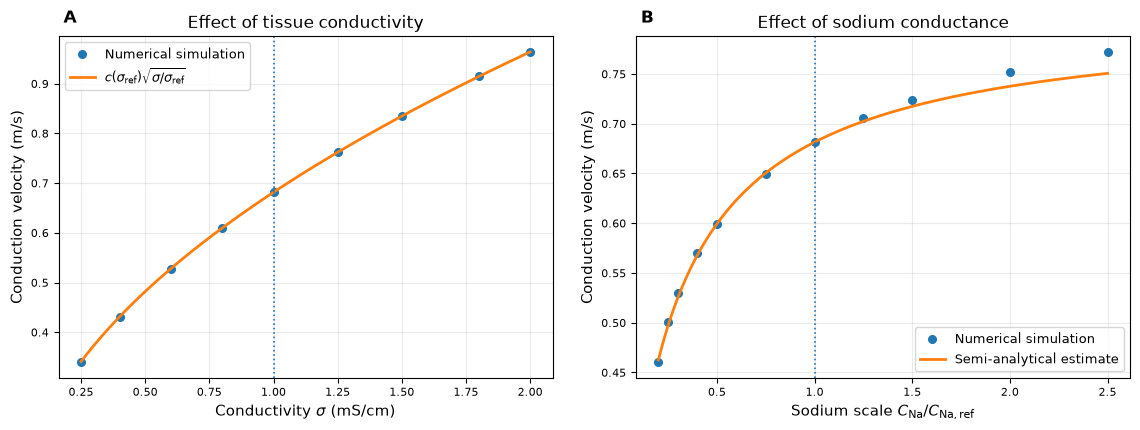

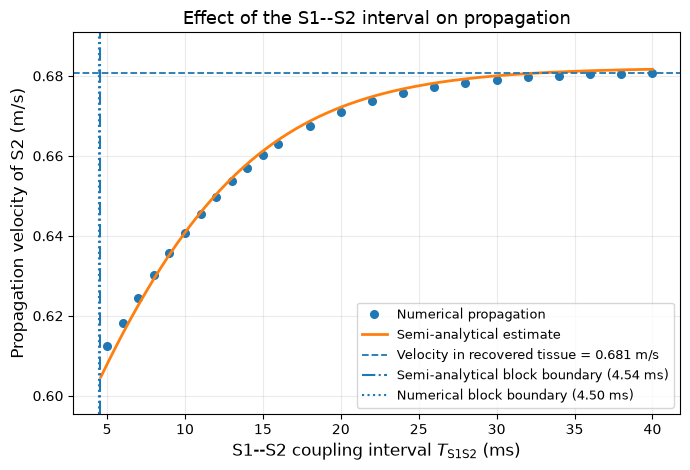


CONDUCTIVITY SWEEP
sigma =  0.25 mS/cm   velocity =  0.3399 m/s
sigma =  0.40 mS/cm   velocity =  0.4305 m/s
sigma =  0.60 mS/cm   velocity =  0.5276 m/s
sigma =  0.80 mS/cm   velocity =  0.6095 m/s
sigma =  1.00 mS/cm   velocity =  0.6816 m/s
sigma =  1.25 mS/cm   velocity =  0.7622 m/s
sigma =  1.50 mS/cm   velocity =  0.8350 m/s
sigma =  1.80 mS/cm   velocity =  0.9148 m/s
sigma =  2.00 mS/cm   velocity =  0.9643 m/s

SODIUM-CONDUCTANCE SWEEP
CNa/CNa_ref = 0.20   velocity =  0.4604 m/s
CNa/CNa_ref = 0.25   velocity =  0.5011 m/s
CNa/CNa_ref = 0.30   velocity =  0.5294 m/s
CNa/CNa_ref = 0.40   velocity =  0.5701 m/s
CNa/CNa_ref = 0.50   velocity =  0.5994 m/s
CNa/CNa_ref = 0.75   velocity =  0.6490 m/s
CNa/CNa_ref = 1.00   velocity =  0.6816 m/s
CNa/CNa_ref = 1.25   velocity =  0.7054 m/s
CNa/CNa_ref = 1.50   velocity =  0.7241 m/s
CNa/CNa_ref = 2.00   velocity =  0.7520 m/s
CNa/CNa_ref = 2.50   velocity =  0.7724 m/s

S1--S2 SWEEP
S1-S2 interval =   5.00 ms   S2 velocity =  0.6125 

In [12]:
# ============================================================
# PROPAGATION VELOCITY ANALYSIS
#
# One combined code containing:
#
#   1. Numerical velocity vs conductivity
#   2. Numerical velocity vs sodium conductance
#   3. Numerical S1--S2 velocity recovery
#   4. Semi-analytical CNa estimate
#   5. Semi-analytical S1--S2 estimate
#
# Produces exactly TWO figures:
#
#   Figure 1:
#       A. Conductivity
#       B. Sodium conductance
#
#   Figure 2:
#       S1--S2 recovery
# ============================================================


# ============================================================
# Imports
# ============================================================

import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from numba import njit


# ============================================================
# Output directory
# ============================================================

try:
    FIGDIR
except NameError:
    FIGDIR = Path("figures_chapter1")

FIGDIR.mkdir(
    exist_ok=True
)


# ============================================================
# Check base model variables
# ============================================================

required_variables = [
    "DT",
    "SIGMA",
    "CHI",
    "CM",
    "V0",
    "VTH",
    "VMAX",
    "GNAB",
    "CNA",
    "CK",
    "GKB",
    "VK",
    "VNA",
    "TAU_M",
    "TAU_H",
    "TAU_K",
    "SPIKE_THRESHOLD"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"{variable_name} was not found. "
            "Run the base membrane/cable model first."
        )


# ============================================================
# ============================================================
# PART I — 1D cable for conductivity and CNa sweeps
# ============================================================
# ============================================================


# ------------------------------------------------------------
# Short 1D cable
# ------------------------------------------------------------

L_SWEEP = 2.0               # cm
NX_SWEEP = 401
T_SWEEP = 45.0              # ms

STIM_AMP_SWEEP = 30.0       # microA/cm^2
STIM_DUR_SWEEP = 0.5        # ms
STIM_WIDTH_SWEEP = 0.10     # cm

X_FIT_MIN = 0.50            # cm
X_FIT_MAX = 1.50            # cm


# ============================================================
# Numerical conduction velocity for one parameter combination
# ============================================================

@njit(cache=False)
def measure_conduction_velocity_1d(
    cna_factor,
    sigma_value
):

    dx = (
        L_SWEEP
        / (NX_SWEEP - 1)
    )

    inv_dx2 = 1.0 / (dx * dx)

    nt = (
        int(
            round(
                T_SWEEP / DT
            )
        )
        + 1
    )

    # --------------------------------------------------------
    # Delay indices
    # --------------------------------------------------------

    km = int(
        round(
            TAU_M / DT
        )
    )

    kh = int(
        round(
            TAU_H / DT
        )
    )

    kk = int(
        round(
            TAU_K / DT
        )
    )

    max_delay = max(
        km,
        kh,
        kk
    )

    buffer_length = (
        max_delay + 1
    )

    # --------------------------------------------------------
    # Diffusion coefficient
    # --------------------------------------------------------

    D_local = (
        sigma_value
        / (CHI * CM)
    )

    # --------------------------------------------------------
    # Initial voltage
    # --------------------------------------------------------

    V = np.full(
        NX_SWEEP,
        V0,
        dtype=np.float64
    )

    Vnew = np.empty_like(V)

    # --------------------------------------------------------
    # History buffer
    # --------------------------------------------------------

    history = np.full(
        (
            buffer_length,
            NX_SWEEP
        ),
        V0,
        dtype=np.float64
    )

    # --------------------------------------------------------
    # Activation time
    # --------------------------------------------------------

    activation = np.full(
        NX_SWEEP,
        np.nan
    )

    stim_end_index = int(
        round(
            STIM_DUR_SWEEP / DT
        )
    )

    # ========================================================
    # Time integration
    # ========================================================

    for it in range(nt - 1):

        history[
            it % buffer_length,
            :
        ] = V

        slot_m = (
            it - km
        ) % buffer_length

        slot_h = (
            it - kh
        ) % buffer_length

        slot_k = (
            it - kk
        ) % buffer_length

        time_now = it * DT

        for p in range(NX_SWEEP):

            # ------------------------------------------------
            # Delayed voltages
            # ------------------------------------------------

            if it >= km:
                Vm = history[
                    slot_m,
                    p
                ]
            else:
                Vm = V0

            if it >= kh:
                Vh = history[
                    slot_h,
                    p
                ]
            else:
                Vh = V0

            if it >= kk:
                Vk_delayed = history[
                    slot_k,
                    p
                ]
            else:
                Vk_delayed = V0

            # ------------------------------------------------
            # Gating variables
            # ------------------------------------------------

            m = max(
                Vm - VTH,
                0.0
            )

            n = max(
                Vk_delayed - VTH,
                0.0
            )

            h = max(
                VMAX
                - max(Vh, VTH),
                0.0
            )

            # ------------------------------------------------
            # Conductances
            # ------------------------------------------------

            GNa = (
                GNAB
                + cna_factor * CNA * m * h
            )

            GK = (
                GKB
                + CK * n
            )

            # ------------------------------------------------
            # Ionic current
            # ------------------------------------------------

            v = V[p]

            Iion = (
                GK * (v - VK)
                + GNa * (v - VNA)
            )

            # ------------------------------------------------
            # Boundary conditions
            # ------------------------------------------------

            left = (
                p - 1
                if p > 0
                else p
            )

            right = (
                p + 1
                if p < NX_SWEEP - 1
                else p
            )

            # ------------------------------------------------
            # Laplacian
            # ------------------------------------------------

            laplacian = (
                V[right]
                - 2.0 * v
                + V[left]
            ) * inv_dx2

            x_here = p * dx

            # ------------------------------------------------
            # Stimulus
            # ------------------------------------------------

            Iext = 0.0

            if (
                it < stim_end_index
                and x_here <= STIM_WIDTH_SWEEP
            ):

                Iext = STIM_AMP_SWEEP

            # ------------------------------------------------
            # Voltage update
            # ------------------------------------------------

            dVdt = (
                (-Iion + Iext) / CM
                + D_local * laplacian
            )

            vn = (
                v
                + DT * dVdt
            )

            Vnew[p] = vn

            # ------------------------------------------------
            # Activation time
            # ------------------------------------------------

            if (
                math.isnan(
                    activation[p]
                )
                and v < SPIKE_THRESHOLD
                and vn >= SPIKE_THRESHOLD
            ):

                fraction = (
                    (
                        SPIKE_THRESHOLD
                        - v
                    )
                    / (
                        vn - v
                        + 1.0e-14
                    )
                )

                activation[p] = (
                    time_now
                    + fraction * DT
                )

        V, Vnew = Vnew, V


    # ========================================================
    # Linear regression
    # ========================================================

    number_of_points = 0

    for p in range(NX_SWEEP):

        x_here = p * dx

        if (
            X_FIT_MIN <= x_here <= X_FIT_MAX
            and not math.isnan(
                activation[p]
            )
        ):

            number_of_points += 1

    if number_of_points < 20:

        return np.nan


    mean_x = 0.0
    mean_t = 0.0

    for p in range(NX_SWEEP):

        x_here = p * dx

        if (
            X_FIT_MIN <= x_here <= X_FIT_MAX
            and not math.isnan(
                activation[p]
            )
        ):

            mean_x += x_here
            mean_t += activation[p]

    mean_x /= number_of_points
    mean_t /= number_of_points


    numerator = 0.0
    denominator = 0.0

    for p in range(NX_SWEEP):

        x_here = p * dx

        if (
            X_FIT_MIN <= x_here <= X_FIT_MAX
            and not math.isnan(
                activation[p]
            )
        ):

            numerator += (
                (x_here - mean_x)
                * (
                    activation[p]
                    - mean_t
                )
            )

            denominator += (
                x_here - mean_x
            ) ** 2


    slope_ms_per_cm = (
        numerator
        / denominator
    )

    # cm/ms -> m/s
    return (
        10.0
        / slope_ms_per_cm
    )


# ============================================================
# Parameter sweeps
# ============================================================

sigma_values = np.array([
    0.25,
    0.40,
    0.60,
    0.80,
    1.00,
    1.25,
    1.50,
    1.80,
    2.00
])


cna_factors = np.array([
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.75,
    1.00,
    1.25,
    1.50,
    2.00,
    2.50
])


# ============================================================
# Compile
# ============================================================

_ = measure_conduction_velocity_1d(
    1.0,
    SIGMA
)


# ============================================================
# Conductivity sweep
# ============================================================

velocity_sigma = np.empty(
    sigma_values.size
)

for i, sigma_value in enumerate(
    sigma_values
):

    velocity_sigma[i] = (
        measure_conduction_velocity_1d(
            cna_factor=1.0,
            sigma_value=sigma_value
        )
    )


# ============================================================
# Sodium sweep
# ============================================================

velocity_cna = np.empty(
    cna_factors.size
)

for i, cna_factor in enumerate(
    cna_factors
):

    velocity_cna[i] = (
        measure_conduction_velocity_1d(
            cna_factor=cna_factor,
            sigma_value=SIGMA
        )
    )


# ============================================================
# Square-root conductivity prediction
# ============================================================

reference_sigma_index = np.argmin(
    np.abs(
        sigma_values - SIGMA
    )
)

reference_velocity_sigma = (
    velocity_sigma[
        reference_sigma_index
    ]
)


sigma_smooth = np.linspace(
    sigma_values.min(),
    sigma_values.max(),
    300
)


sqrt_sigma_prediction = (
    reference_velocity_sigma
    * np.sqrt(
        sigma_smooth / SIGMA
    )
)


# ============================================================
# ============================================================
# PART II — Numerical S1--S2 velocity sweep
# ============================================================
# ============================================================


# ------------------------------------------------------------
# Cable
# ------------------------------------------------------------

L_S1S2 = 2.0
NX_S1S2 = 301

STIM_AMP_S1S2 = 30.0
STIM_DUR_S1S2 = 1.0
STIM_WIDTH_S1S2 = 0.10

X_FIT_MIN_S1S2 = 0.60
X_FIT_MAX_S1S2 = 1.40


# ------------------------------------------------------------
# S1--S2 intervals
# ------------------------------------------------------------

S1S2_INTERVALS = np.concatenate([
    np.arange(4.0, 16.0, 1.0),
    np.arange(16.0, 42.0, 2.0)
])


# ============================================================
# Numerical S2 velocity
# ============================================================

@njit(cache=False)
def measure_s2_velocity(
    s1s2_interval
):

    dx = (
        L_S1S2
        / (NX_S1S2 - 1)
    )

    inv_dx2 = 1.0 / (
        dx * dx
    )

    total_time = (
        s1s2_interval
        + 35.0
    )

    nt = (
        int(
            round(
                total_time / DT
            )
        )
        + 1
    )

    # --------------------------------------------------------
    # Delay indices
    # --------------------------------------------------------

    km = int(
        round(
            TAU_M / DT
        )
    )

    kh = int(
        round(
            TAU_H / DT
        )
    )

    kk = int(
        round(
            TAU_K / DT
        )
    )

    max_delay = max(
        km,
        kh,
        kk
    )

    buffer_length = (
        max_delay + 1
    )


    # --------------------------------------------------------
    # Diffusion
    # --------------------------------------------------------

    D_local = (
        SIGMA
        / (CHI * CM)
    )


    # --------------------------------------------------------
    # Initial conditions
    # --------------------------------------------------------

    V = np.full(
        NX_S1S2,
        V0,
        dtype=np.float64
    )

    Vnew = np.empty_like(V)


    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history = np.full(
        (
            buffer_length,
            NX_S1S2
        ),
        V0,
        dtype=np.float64
    )


    # --------------------------------------------------------
    # Activation times
    # --------------------------------------------------------

    activation_s1 = np.full(
        NX_S1S2,
        np.nan
    )

    repolarization_s1 = np.full(
        NX_S1S2,
        np.nan
    )

    activation_s2 = np.full(
        NX_S1S2,
        np.nan
    )


    # --------------------------------------------------------
    # Stimulus timing
    # --------------------------------------------------------

    s1_end_index = int(
        round(
            STIM_DUR_S1S2 / DT
        )
    )

    s2_start_index = int(
        round(
            s1s2_interval / DT
        )
    )

    s2_end_index = int(
        round(
            (
                s1s2_interval
                + STIM_DUR_S1S2
            )
            / DT
        )
    )


    # ========================================================
    # Time integration
    # ========================================================

    for it in range(nt - 1):

        history[
            it % buffer_length,
            :
        ] = V


        slot_m = (
            it - km
        ) % buffer_length

        slot_h = (
            it - kh
        ) % buffer_length

        slot_k = (
            it - kk
        ) % buffer_length


        time_now = it * DT


        for p in range(NX_S1S2):

            # ------------------------------------------------
            # Delayed variables
            # ------------------------------------------------

            if it >= km:
                Vm = history[
                    slot_m,
                    p
                ]
            else:
                Vm = V0


            if it >= kh:
                Vh = history[
                    slot_h,
                    p
                ]
            else:
                Vh = V0


            if it >= kk:
                Vk_delayed = history[
                    slot_k,
                    p
                ]
            else:
                Vk_delayed = V0


            # ------------------------------------------------
            # Gating
            # ------------------------------------------------

            m = max(
                Vm - VTH,
                0.0
            )

            n = max(
                Vk_delayed - VTH,
                0.0
            )

            h = max(
                VMAX
                - max(Vh, VTH),
                0.0
            )


            # ------------------------------------------------
            # Conductances
            # ------------------------------------------------

            GNa = (
                GNAB
                + CNA * m * h
            )

            GK = (
                GKB
                + CK * n
            )


            # ------------------------------------------------
            # Ionic current
            # ------------------------------------------------

            v = V[p]

            Iion = (
                GK * (v - VK)
                + GNa * (v - VNA)
            )


            # ------------------------------------------------
            # Boundary conditions
            # ------------------------------------------------

            left = (
                p - 1
                if p > 0
                else p
            )

            right = (
                p + 1
                if p < NX_S1S2 - 1
                else p
            )


            # ------------------------------------------------
            # Laplacian
            # ------------------------------------------------

            laplacian = (
                V[right]
                - 2.0 * v
                + V[left]
            ) * inv_dx2


            x_here = p * dx

            Iext = 0.0


            # ------------------------------------------------
            # Stimulation
            # ------------------------------------------------

            if (
                x_here
                <= STIM_WIDTH_S1S2
            ):

                # S1
                if it < s1_end_index:

                    Iext = (
                        STIM_AMP_S1S2
                    )

                # S2
                elif (
                    s2_start_index
                    <= it
                    < s2_end_index
                ):

                    Iext = (
                        STIM_AMP_S1S2
                    )


            # ------------------------------------------------
            # Voltage update
            # ------------------------------------------------

            vn = (
                v
                + DT * (
                    (-Iion + Iext)
                    / CM
                    + D_local
                    * laplacian
                )
            )

            Vnew[p] = vn


            # =================================================
            # Upward crossing
            # =================================================

            if (
                v < SPIKE_THRESHOLD
                and vn >= SPIKE_THRESHOLD
            ):

                fraction = (
                    (
                        SPIKE_THRESHOLD
                        - v
                    )
                    / (
                        vn - v
                        + 1.0e-14
                    )
                )

                crossing_time = (
                    time_now
                    + fraction * DT
                )


                if math.isnan(
                    activation_s1[p]
                ):

                    activation_s1[p] = (
                        crossing_time
                    )

                elif (
                    not math.isnan(
                        repolarization_s1[p]
                    )
                    and math.isnan(
                        activation_s2[p]
                    )
                ):

                    activation_s2[p] = (
                        crossing_time
                    )


            # =================================================
            # Downward crossing
            # =================================================

            elif (
                v >= SPIKE_THRESHOLD
                and vn < SPIKE_THRESHOLD
            ):

                if (
                    not math.isnan(
                        activation_s1[p]
                    )
                    and math.isnan(
                        repolarization_s1[p]
                    )
                ):

                    fraction = (
                        (
                            v
                            - SPIKE_THRESHOLD
                        )
                        / (
                            v - vn
                            + 1.0e-14
                        )
                    )

                    repolarization_s1[p] = (
                        time_now
                        + fraction * DT
                    )


        V, Vnew = Vnew, V


    # ========================================================
    # Select fitting region
    # ========================================================

    expected_points = 0
    valid_points = 0

    mean_x = 0.0
    mean_t = 0.0


    for p in range(
        NX_S1S2
    ):

        x_here = p * dx

        if (
            X_FIT_MIN_S1S2
            <= x_here
            <= X_FIT_MAX_S1S2
        ):

            expected_points += 1

            if not math.isnan(
                activation_s2[p]
            ):

                valid_points += 1

                mean_x += x_here
                mean_t += (
                    activation_s2[p]
                )


    if (
        valid_points
        != expected_points
        or valid_points < 10
    ):

        return np.nan


    mean_x /= valid_points
    mean_t /= valid_points


    numerator = 0.0
    denominator = 0.0


    for p in range(
        NX_S1S2
    ):

        x_here = p * dx

        if (
            X_FIT_MIN_S1S2
            <= x_here
            <= X_FIT_MAX_S1S2
        ):

            numerator += (
                (x_here - mean_x)
                * (
                    activation_s2[p]
                    - mean_t
                )
            )

            denominator += (
                x_here - mean_x
            ) ** 2


    slope_ms_per_cm = (
        numerator
        / denominator
    )


    return (
        10.0
        / slope_ms_per_cm
    )


# ============================================================
# Compile
# ============================================================

_ = measure_s2_velocity(
    30.0
)


# ============================================================
# Numerical S1--S2 sweep
# ============================================================

successful_intervals = []
s2_velocities = []
blocked_intervals = []


for interval in S1S2_INTERVALS:

    velocity = (
        measure_s2_velocity(
            interval
        )
    )

    if np.isfinite(
        velocity
    ):

        successful_intervals.append(
            interval
        )

        s2_velocities.append(
            velocity
        )

    else:

        blocked_intervals.append(
            interval
        )


successful_intervals = np.asarray(
    successful_intervals,
    dtype=float
)

s2_velocities = np.asarray(
    s2_velocities,
    dtype=float
)

blocked_intervals = np.asarray(
    blocked_intervals,
    dtype=float
)


if (
    successful_intervals.size
    == 0
):

    raise RuntimeError(
        "No S2 wave propagated."
    )


# ============================================================
# Fully recovered velocity
# ============================================================

if (
    "cv_m_per_s" in globals()
    and np.isfinite(
        cv_m_per_s
    )
):

    fully_recovered_velocity = float(
        cv_m_per_s
    )

else:

    fully_recovered_velocity = float(
        s2_velocities[-1]
    )


# ============================================================
# ============================================================
# PART III — Semi-analytical estimates
# ============================================================
# ============================================================


# ------------------------------------------------------------
# Probe
# ------------------------------------------------------------

X_PROBE_ANALYTICAL = 1.0


# ------------------------------------------------------------
# Axial-current averaging interval
# ------------------------------------------------------------

V_AXIAL_MIN = (
    VTH - 5.0
)

V_AXIAL_MAX = VTH


# ------------------------------------------------------------
# Sodium upstroke interval
# ------------------------------------------------------------

DELTA_V_UPSTROKE = 1.0


# ------------------------------------------------------------
# Travel-time correction
# ------------------------------------------------------------

USE_TRAVEL_TIME_CORRECTION = True


# ============================================================
# Reference wave
# ============================================================

@njit(cache=False)
def record_reference_wavefront():

    dx = (
        L_S1S2
        / (NX_S1S2 - 1)
    )

    total_time = (
        float(
            np.max(
                S1S2_INTERVALS
            )
        )
        + 90.0
    )

    nt = (
        int(
            round(
                total_time / DT
            )
        )
        + 1
    )


    km = int(
        round(
            TAU_M / DT
        )
    )

    kh = int(
        round(
            TAU_H / DT
        )
    )

    kk = int(
        round(
            TAU_K / DT
        )
    )


    max_delay = max(
        km,
        kh,
        kk
    )

    buffer_length = (
        max_delay + 1
    )


    D_local = (
        SIGMA
        / (CHI * CM)
    )

    inv_dx2 = 1.0 / (
        dx * dx
    )


    probe_index = int(
        round(
            X_PROBE_ANALYTICAL
            / dx
        )
    )

    probe_index = max(
        1,
        min(
            NX_S1S2 - 2,
            probe_index
        )
    )


    V = np.full(
        NX_S1S2,
        V0,
        dtype=np.float64
    )

    Vnew = np.empty_like(V)


    history = np.full(
        (
            buffer_length,
            NX_S1S2
        ),
        V0,
        dtype=np.float64
    )


    voltage_trace = np.empty(
        nt,
        dtype=np.float64
    )

    axial_current_trace = np.empty(
        nt,
        dtype=np.float64
    )


    activation_time = np.nan


    stim_end_index = int(
        round(
            STIM_DUR_S1S2 / DT
        )
    )


    # ========================================================
    # Time integration
    # ========================================================

    for it in range(
        nt - 1
    ):

        history[
            it % buffer_length,
            :
        ] = V


        slot_m = (
            it - km
        ) % buffer_length

        slot_h = (
            it - kh
        ) % buffer_length

        slot_k = (
            it - kk
        ) % buffer_length


        time_now = it * DT


        voltage_trace[it] = (
            V[probe_index]
        )


        for p in range(
            NX_S1S2
        ):

            Vm = (
                history[
                    slot_m,
                    p
                ]
                if it >= km
                else V0
            )

            Vh = (
                history[
                    slot_h,
                    p
                ]
                if it >= kh
                else V0
            )

            Vk_delayed = (
                history[
                    slot_k,
                    p
                ]
                if it >= kk
                else V0
            )


            m = max(
                Vm - VTH,
                0.0
            )

            n = max(
                Vk_delayed - VTH,
                0.0
            )

            h = max(
                VMAX
                - max(Vh, VTH),
                0.0
            )


            GNa = (
                GNAB
                + CNA * m * h
            )

            GK = (
                GKB
                + CK * n
            )


            v = V[p]


            Iion = (
                GK * (v - VK)
                + GNa * (v - VNA)
            )


            left = (
                p - 1
                if p > 0
                else p
            )

            right = (
                p + 1
                if p < NX_S1S2 - 1
                else p
            )


            laplacian = (
                V[right]
                - 2.0 * v
                + V[left]
            ) * inv_dx2


            if p == probe_index:

                axial_current_trace[it] = (
                    CM
                    * D_local
                    * laplacian
                )


            x_here = p * dx

            Iext = 0.0


            if (
                it < stim_end_index
                and x_here
                <= STIM_WIDTH_S1S2
            ):

                Iext = (
                    STIM_AMP_S1S2
                )


            vn = (
                v
                + DT * (
                    (-Iion + Iext)
                    / CM
                    + D_local
                    * laplacian
                )
            )


            Vnew[p] = vn


            if (
                p == probe_index
                and math.isnan(
                    activation_time
                )
                and v < SPIKE_THRESHOLD
                and vn >= SPIKE_THRESHOLD
            ):

                fraction = (
                    (
                        SPIKE_THRESHOLD
                        - v
                    )
                    / (
                        vn - v
                        + 1.0e-14
                    )
                )

                activation_time = (
                    time_now
                    + fraction * DT
                )


        V, Vnew = Vnew, V


    voltage_trace[-1] = (
        V[probe_index]
    )

    axial_current_trace[-1] = (
        axial_current_trace[-2]
    )


    return (
        voltage_trace,
        axial_current_trace,
        activation_time
    )


# ============================================================
# Record reference wave
# ============================================================

(
    voltage_reference,
    axial_current_reference,
    t_activation_reference
) = record_reference_wavefront()


time_reference = (
    np.arange(
        voltage_reference.size
    )
    * DT
)


if not np.isfinite(
    t_activation_reference
):

    raise RuntimeError(
        "The reference wave did not reach "
        "the analytical probe position."
    )


# ============================================================
# Representative axial current
# ============================================================

dVdt_reference = np.gradient(
    voltage_reference,
    DT
)


axial_mask = (
    (time_reference
     < t_activation_reference)

    & (
        voltage_reference
        >= V_AXIAL_MIN
    )

    & (
        voltage_reference
        <= V_AXIAL_MAX
    )

    & (
        dVdt_reference
        > 0.0
    )

    & (
        axial_current_reference
        > 0.0
    )
)


if np.count_nonzero(
    axial_mask
) < 5:

    axial_mask = (
        (time_reference
         < t_activation_reference)

        & (
            voltage_reference
            >= V0 + 1.0
        )

        & (
            voltage_reference
            <= VTH
        )

        & (
            dVdt_reference
            > 0.0
        )

        & (
            axial_current_reference
            > 0.0
        )
    )


if np.count_nonzero(
    axial_mask
) < 5:

    raise RuntimeError(
        "Could not estimate the reference axial current."
    )


IAX_REFERENCE = np.mean(
    axial_current_reference[
        axial_mask
    ]
)


# ============================================================
# Sodium upstroke integral
# ============================================================

V_UPSTROKE_START = (
    VTH
    + DELTA_V_UPSTROKE
)

V_UPSTROKE_END = (
    SPIKE_THRESHOLD
)


if not (
    VTH
    < V_UPSTROKE_START
    < V_UPSTROKE_END
    < VNA
):

    raise RuntimeError(
        "The selected upstroke interval is invalid."
    )


upstroke_logarithm = np.log(
    (
        (
            V_UPSTROKE_END
            - VTH
        )
        * (
            VNA
            - V_UPSTROKE_START
        )
    )
    /
    (
        (
            V_UPSTROKE_START
            - VTH
        )
        * (
            VNA
            - V_UPSTROKE_END
        )
    )
)


B_H = (
    CM
    * upstroke_logarithm
    /
    (
        CNA
        * (
            VNA
            - VTH
        )
    )
)


H_FULLY_RECOVERED = max(
    VMAX
    - max(V0, VTH),
    0.0
)


# ============================================================
# Effective subthreshold parameters
# ============================================================

def effective_subthreshold_parameters(
    n_value
):

    potassium_conductance = (
        GKB
        + CK * n_value
    )

    conductance = (
        GNAB
        + potassium_conductance
    )

    equilibrium_voltage = (
        GNAB * VNA
        + potassium_conductance * VK
    ) / conductance

    return (
        conductance,
        equilibrium_voltage
    )


# ============================================================
# Charging time
# ============================================================

def charging_time_to_threshold(
    voltage_initial,
    n_value,
    axial_current
):

    if voltage_initial >= VTH:

        return 0.0


    conductance, equilibrium_voltage = (
        effective_subthreshold_parameters(
            n_value
        )
    )


    numerator = (
        axial_current
        - conductance
        * (
            voltage_initial
            - equilibrium_voltage
        )
    )


    denominator = (
        axial_current
        - conductance
        * (
            VTH
            - equilibrium_voltage
        )
    )


    if denominator <= 0.0:

        return np.inf


    if numerator <= denominator:

        return np.inf


    membrane_time_constant = (
        CM
        / conductance
    )


    return (
        membrane_time_constant
        * np.log(
            numerator
            / denominator
        )
    )


# ============================================================
# Fully recovered reference activation
# ============================================================

tau_charge_recovered = (
    charging_time_to_threshold(
        voltage_initial=V0,
        n_value=0.0,
        axial_current=IAX_REFERENCE
    )
)


tau_up_recovered = (
    TAU_M
    + B_H
    / H_FULLY_RECOVERED
)


tau_activation_recovered = (
    tau_charge_recovered
    + tau_up_recovered
)


if not np.isfinite(
    tau_activation_recovered
):

    raise RuntimeError(
        "The reference axial current is too small "
        "to charge the resting membrane to threshold."
    )


# ============================================================
# ============================================================
# Semi-analytical CNa sweep
# ============================================================
# ============================================================


velocity_cna = np.asarray(
    velocity_cna,
    dtype=float
)

cna_factors = np.asarray(
    cna_factors,
    dtype=float
)


finite_cna = (
    np.isfinite(
        velocity_cna
    )
    & (
        cna_factors > 0.0
    )
)


if np.count_nonzero(
    finite_cna
) == 0:

    raise RuntimeError(
        "No valid CNa numerical velocities were found."
    )


reference_cna_velocity = np.interp(
    1.0,
    cna_factors[
        finite_cna
    ],
    velocity_cna[
        finite_cna
    ]
)


# ============================================================
# Analytical CNa velocity
# ============================================================

def analytical_cna_velocity(
    alpha
):

    if alpha <= 0.0:

        return np.nan


    tau_up = (
        TAU_M
        + B_H
        / (
            alpha
            * H_FULLY_RECOVERED
        )
    )


    tau_total = (
        tau_charge_recovered
        + tau_up
    )


    return (
        reference_cna_velocity
        * np.sqrt(
            tau_activation_recovered
            / tau_total
        )
    )


analytical_velocity_cna = np.array([
    analytical_cna_velocity(
        alpha
    )
    for alpha in cna_factors
])


cna_dense = np.linspace(
    cna_factors.min(),
    cna_factors.max(),
    300
)


analytical_velocity_cna_dense = np.array([
    analytical_cna_velocity(
        alpha
    )
    for alpha in cna_dense
])


# ============================================================
# ============================================================
# S1--S2 recovery model
# ============================================================
# ============================================================


def sample_reference_voltage(
    relative_time
):

    absolute_time = (
        t_activation_reference
        + relative_time
    )

    return np.interp(
        absolute_time,
        time_reference,
        voltage_reference
    )


# ============================================================
# Recovery state
# ============================================================

def recovery_state(
    local_interval
):

    voltage_now = (
        sample_reference_voltage(
            local_interval
        )
    )


    voltage_h_delay = (
        sample_reference_voltage(
            local_interval
            - TAU_H
        )
    )


    voltage_k_delay = (
        sample_reference_voltage(
            local_interval
            - TAU_K
        )
    )


    h_value = max(
        VMAX
        - max(
            voltage_h_delay,
            VTH
        ),
        0.0
    )


    n_value = max(
        voltage_k_delay
        - VTH,
        0.0
    )


    return (
        voltage_now,
        h_value,
        n_value
    )


# ============================================================
# Activation time from recovery state
# ============================================================

def activation_time_from_recovery(
    local_interval
):

    (
        voltage_now,
        h_value,
        n_value
    ) = recovery_state(
        local_interval
    )


    if h_value <= 1.0e-10:

        return np.inf


    tau_charge = (
        charging_time_to_threshold(
            voltage_initial=voltage_now,
            n_value=n_value,
            axial_current=IAX_REFERENCE
        )
    )


    if not np.isfinite(
        tau_charge
    ):

        return np.inf


    tau_up = (
        TAU_M
        + B_H / h_value
    )


    return (
        tau_charge
        + tau_up
    )


# ============================================================
# Fully recovered S2 velocity
# ============================================================

reference_interval_velocity = float(
    fully_recovered_velocity
)


# ============================================================
# Velocity from local recovery interval
# ============================================================

def velocity_from_local_interval(
    local_interval
):

    tau_local = (
        activation_time_from_recovery(
            local_interval
        )
    )


    if not np.isfinite(
        tau_local
    ):

        return np.nan


    return (
        reference_interval_velocity
        * np.sqrt(
            tau_activation_recovered
            / tau_local
        )
    )


# ============================================================
# Convert imposed interval to local interval
# ============================================================

def velocity_from_imposed_interval(
    imposed_interval,
    use_travel_correction=(
        USE_TRAVEL_TIME_CORRECTION
    )
):

    local_interval = float(
        imposed_interval
    )


    if not use_travel_correction:

        velocity = (
            velocity_from_local_interval(
                local_interval
            )
        )

        return (
            velocity,
            local_interval
        )


    # --------------------------------------------------------
    # Damped fixed-point iteration
    # --------------------------------------------------------

    for _ in range(100):

        velocity = (
            velocity_from_local_interval(
                local_interval
            )
        )


        if (
            not np.isfinite(
                velocity
            )
            or velocity <= 0.0
        ):

            return (
                np.nan,
                local_interval
            )


        corrected_interval = (
            imposed_interval
            + 10.0
            * X_PROBE_ANALYTICAL
            * (
                1.0 / velocity
                - 1.0
                / reference_interval_velocity
            )
        )


        corrected_interval = max(
            0.0,
            corrected_interval
        )


        new_local_interval = (
            0.6 * local_interval
            + 0.4 * corrected_interval
        )


        if abs(
            new_local_interval
            - local_interval
        ) < 1.0e-6:

            local_interval = (
                new_local_interval
            )

            break


        local_interval = (
            new_local_interval
        )


    velocity = (
        velocity_from_local_interval(
            local_interval
        )
    )


    return (
        velocity,
        local_interval
    )


# ============================================================
# Dense analytical interval curve
# ============================================================

interval_dense = np.linspace(
    float(
        np.min(
            S1S2_INTERVALS
        )
    ),
    float(
        np.max(
            S1S2_INTERVALS
        )
    ),
    300
)


analytical_interval_dense = np.empty_like(
    interval_dense
)

analytical_local_interval_dense = np.empty_like(
    interval_dense
)


for i, interval in enumerate(
    interval_dense
):

    (
        velocity,
        local_interval
    ) = velocity_from_imposed_interval(
        interval
    )

    analytical_interval_dense[i] = (
        velocity
    )

    analytical_local_interval_dense[i] = (
        local_interval
    )


# ============================================================
# Analytical values at tested intervals
# ============================================================

analytical_interval_tested = np.empty(
    len(S1S2_INTERVALS)
)

analytical_local_interval_tested = np.empty(
    len(S1S2_INTERVALS)
)


for i, interval in enumerate(
    S1S2_INTERVALS
):

    (
        velocity,
        local_interval
    ) = velocity_from_imposed_interval(
        float(interval)
    )

    analytical_interval_tested[i] = (
        velocity
    )

    analytical_local_interval_tested[i] = (
        local_interval
    )


# ============================================================
# ============================================================
# PART IV — Error measures and block boundaries
# ============================================================
# ============================================================


# ------------------------------------------------------------
# CNa RMSE
# ------------------------------------------------------------

cna_comparison_mask = (
    finite_cna
    & np.isfinite(
        analytical_velocity_cna
    )
)


cna_rmse = np.sqrt(
    np.mean(
        (
            analytical_velocity_cna[
                cna_comparison_mask
            ]
            - velocity_cna[
                cna_comparison_mask
            ]
        ) ** 2
    )
)


# ------------------------------------------------------------
# S1--S2 RMSE
# ------------------------------------------------------------

interval_predictions_successful = np.array([
    velocity_from_imposed_interval(
        float(interval)
    )[0]
    for interval in successful_intervals
])


interval_comparison_mask = (
    np.isfinite(
        s2_velocities
    )
    & np.isfinite(
        interval_predictions_successful
    )
)


if np.count_nonzero(
    interval_comparison_mask
) > 0:

    interval_rmse = np.sqrt(
        np.mean(
            (
                interval_predictions_successful[
                    interval_comparison_mask
                ]
                - s2_velocities[
                    interval_comparison_mask
                ]
            ) ** 2
        )
    )

else:

    interval_rmse = np.nan


# ============================================================
# Predicted S1--S2 block boundary
# ============================================================

finite_prediction = np.isfinite(
    analytical_interval_dense
)

predicted_block_boundary = np.nan


transition_indices = np.where(
    (~finite_prediction[:-1])
    & finite_prediction[1:]
)[0]


if transition_indices.size > 0:

    transition_index = (
        transition_indices[-1]
    )

    predicted_block_boundary = (
        0.5
        * (
            interval_dense[
                transition_index
            ]
            + interval_dense[
                transition_index + 1
            ]
        )
    )


elif np.all(
    finite_prediction
):

    predicted_block_boundary = np.nan


else:

    predicted_block_boundary = (
        interval_dense[-1]
    )


# ============================================================
# Numerical block boundary
# ============================================================

numerical_block_boundary = np.nan


if (
    blocked_intervals.size > 0
    and successful_intervals.size > 0
):

    last_blocked_interval = np.max(
        blocked_intervals
    )

    first_successful_interval = np.min(
        successful_intervals
    )


    if (
        last_blocked_interval
        < first_successful_interval
    ):

        numerical_block_boundary = (
            0.5
            * (
                last_blocked_interval
                + first_successful_interval
            )
        )


# ============================================================
# ============================================================
# FIGURE 1
# Conductivity + sodium strength
# ============================================================
# ============================================================


fig1, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.4)
)


# ============================================================
# Panel A — conductivity
# ============================================================

ax = axes[0]


ax.plot(
    sigma_values,
    velocity_sigma,
    "o",
    color="#1f77b4",
    markersize=5.5,
    label="Numerical simulation"
)


ax.plot(
    sigma_smooth,
    sqrt_sigma_prediction,
    "-",
    color="#ff7f0e",
    linewidth=2.0,
    label=(
        r"$c(\sigma_{\mathrm{ref}})"
        r"\sqrt{\sigma/\sigma_{\mathrm{ref}}}$"
    )
)


ax.axvline(
    SIGMA,
    color="#1f77b4",
    linestyle=":",
    linewidth=1.2
)


ax.set_xlabel(
    r"Conductivity $\sigma$ (mS/cm)",
    fontsize=11
)

ax.set_ylabel(
    "Conduction velocity (m/s)",
    fontsize=11
)


ax.set_title(
    "Effect of tissue conductivity",
    fontsize=12
)


ax.grid(
    alpha=0.25
)


ax.tick_params(
    axis="both",
    which="major",
    labelsize=8
)


ax.legend(
    fontsize=9,
    loc="upper left"
)


# Panel label
ax.text(
    0.01,
    1.04,
    "A",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# Panel B — sodium
# ============================================================

ax = axes[1]


ax.plot(
    cna_factors,
    velocity_cna,
    "o",
    color="#1f77b4",
    markersize=5.5,
    label="Numerical simulation"
)


ax.plot(
    cna_dense,
    analytical_velocity_cna_dense,
    "-",
    color="#ff7f0e",
    linewidth=2.0,
    label="Semi-analytical estimate"
)


ax.axvline(
    1.0,
    color="#1f77b4",
    linestyle=":",
    linewidth=1.2
)


ax.set_xlabel(
    r"Sodium scale "
    r"$C_{\mathrm{Na}}/C_{\mathrm{Na,ref}}$",
    fontsize=11
)


ax.set_ylabel(
    "Conduction velocity (m/s)",
    fontsize=11
)


ax.set_title(
    "Effect of sodium conductance",
    fontsize=12
)


ax.grid(
    alpha=0.25
)


ax.tick_params(
    axis="both",
    which="major",
    labelsize=8
)


ax.legend(
    fontsize=9,
    loc="lower right"
)


# Panel label
ax.text(
    0.01,
    1.04,
    "B",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold"
)


fig1.tight_layout(
    w_pad=2.0
)


# ------------------------------------------------------------
# Save Figure 1
# ------------------------------------------------------------

output_path_1 = (
    FIGDIR
    / "velocity_vs_sigma_and_sodium.png"
)


fig1.savefig(
    output_path_1,
    dpi=220,
    bbox_inches="tight"
)


# ============================================================
# ============================================================
# FIGURE 2
# S1--S2 recovery
# ============================================================
# ============================================================


fig2, ax = plt.subplots(
    figsize=(7.0, 4.8)
)


# ============================================================
# Numerical S2 propagation
# ============================================================

ax.plot(
    successful_intervals,
    s2_velocities,
    "o",
    color="#1f77b4",
    markersize=5.5,
    label="Numerical propagation"
)


# ============================================================
# Semi-analytical curve
# ============================================================

ax.plot(
    interval_dense[
        finite_prediction
    ],
    analytical_interval_dense[
        finite_prediction
    ],
    "-",
    color="#ff7f0e",
    linewidth=2.0,
    label="Semi-analytical estimate"
)


# ============================================================
# Fully recovered velocity
# ============================================================

ax.axhline(
    reference_interval_velocity,
    color="#1f77b4",
    linestyle="--",
    linewidth=1.3,
    label=(
        "Velocity in recovered tissue "
        f"= {reference_interval_velocity:.3f} m/s"
    )
)


# ============================================================
# Predicted block boundary
# ============================================================

if np.isfinite(
    predicted_block_boundary
):

    ax.axvline(
        predicted_block_boundary,
        color="#1f77b4",
        linestyle="-.",
        linewidth=1.5,
        label=(
            "Semi-analytical block boundary "
            f"({predicted_block_boundary:.2f} ms)"
        )
    )


# ============================================================
# Numerical block boundary
# ============================================================

if np.isfinite(
    numerical_block_boundary
):

    ax.axvline(
        numerical_block_boundary,
        color="#1f77b4",
        linestyle=":",
        linewidth=1.5,
        label=(
            "Numerical block boundary "
            f"({numerical_block_boundary:.2f} ms)"
        )
    )


# ============================================================
# Y limits
# ============================================================

finite_interval_velocities = np.concatenate([
    s2_velocities[
        np.isfinite(
            s2_velocities
        )
    ],

    analytical_interval_dense[
        np.isfinite(
            analytical_interval_dense
        )
    ],

    np.array([
        reference_interval_velocity
    ])
])


velocity_min = np.min(
    finite_interval_velocities
)

velocity_max = np.max(
    finite_interval_velocities
)

velocity_range = (
    velocity_max
    - velocity_min
)


if velocity_range <= 1.0e-12:

    velocity_range = (
        0.05
        * velocity_max
    )


y_margin = (
    0.12
    * velocity_range
)


ax.set_ylim(
    velocity_min - y_margin,
    velocity_max + y_margin
)


# ============================================================
# Labels
# ============================================================

ax.set_xlabel(
    r"S1--S2 coupling interval "
    r"$T_{\mathrm{S1S2}}$ (ms)",
    fontsize=12
)


ax.set_ylabel(
    "Propagation velocity of S2 (m/s)",
    fontsize=12
)


ax.set_title(
    "Effect of the S1--S2 interval on propagation",
    fontsize=13
)


# ============================================================
# Grid
# ============================================================

ax.grid(
    alpha=0.25
)


# ============================================================
# Tick labels
# ============================================================

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10
)


# ============================================================
# Legend
# ============================================================

ax.legend(
    fontsize=9,
    loc="lower right"
)


fig2.tight_layout()


# ------------------------------------------------------------
# Save Figure 2
# ------------------------------------------------------------

output_path_2 = (
    FIGDIR
    / "analytical_velocity_estimates_improved.png"
)


fig2.savefig(
    output_path_2,
    dpi=220,
    bbox_inches="tight"
)


# ============================================================
# Show exactly the two requested figures
# ============================================================

plt.show()


# ============================================================
# Numerical output
# ============================================================

print()
print("=" * 60)
print("CONDUCTIVITY SWEEP")
print("=" * 60)

for sigma_value, velocity in zip(
    sigma_values,
    velocity_sigma
):

    print(
        f"sigma = {sigma_value:5.2f} mS/cm"
        f"   velocity = {velocity:7.4f} m/s"
    )


print()
print("=" * 60)
print("SODIUM-CONDUCTANCE SWEEP")
print("=" * 60)

for factor, velocity in zip(
    cna_factors,
    velocity_cna
):

    print(
        f"CNa/CNa_ref = {factor:4.2f}"
        f"   velocity = {velocity:7.4f} m/s"
    )


print()
print("=" * 60)
print("S1--S2 SWEEP")
print("=" * 60)

for interval, velocity in zip(
    successful_intervals,
    s2_velocities
):

    print(
        f"S1-S2 interval = {interval:6.2f} ms"
        f"   S2 velocity = {velocity:7.4f} m/s"
    )


if blocked_intervals.size > 0:

    print()
    print(
        "Blocked S1--S2 intervals:"
    )

    for interval in blocked_intervals:

        print(
            f"   {interval:6.2f} ms"
        )


print()
print("=" * 60)
print("SEMI-ANALYTICAL RESULTS")
print("=" * 60)

print(
    f"CNa RMSE = {cna_rmse:.6f} m/s"
)

print(
    f"S1-S2 RMSE = {interval_rmse:.6f} m/s"
)


if np.isfinite(
    predicted_block_boundary
):

    print(
        "Semi-analytical block boundary = "
        f"{predicted_block_boundary:.3f} ms"
    )


if np.isfinite(
    numerical_block_boundary
):

    print(
        "Numerical block boundary = "
        f"{numerical_block_boundary:.3f} ms"
    )


print()
print(
    f"Figure 1 saved to: {output_path_1}"
)

print(
    f"Figure 2 saved to: {output_path_2}"
)

# Fig. 2.8: Potassium scale

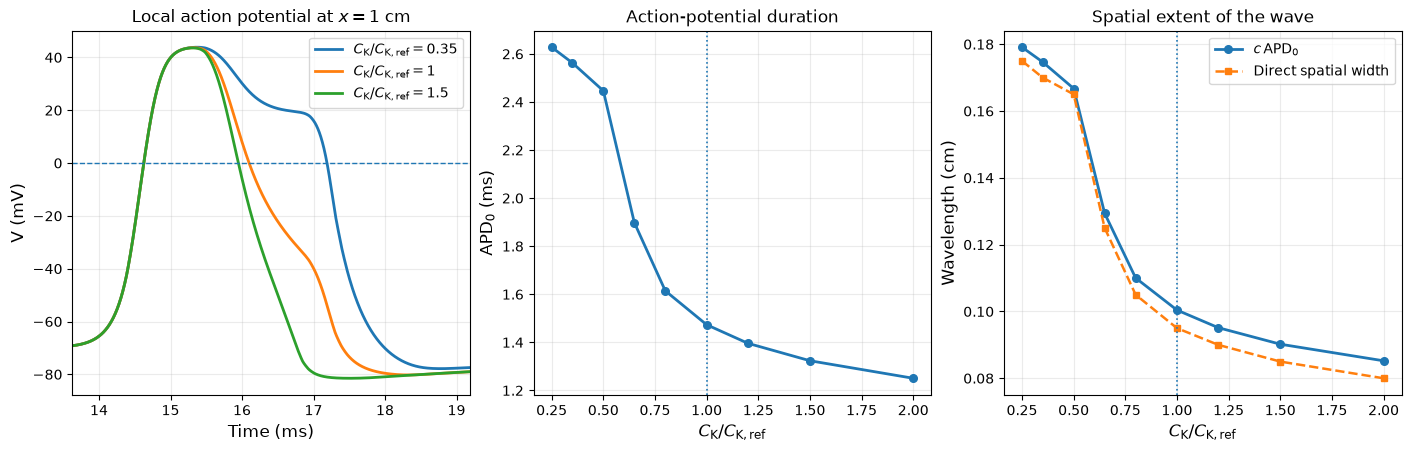

Potassium scale, velocity, APD, and wavelength
--------------------------------------------------------
CK/CK_ref = 0.25   CV =  0.6816 m/s   APD0 =  2.6277 ms   c*APD0 =  0.1791 cm   direct =  0.1750 cm
CK/CK_ref = 0.35   CV =  0.6816 m/s   APD0 =  2.5627 ms   c*APD0 =  0.1747 cm   direct =  0.1700 cm
CK/CK_ref = 0.50   CV =  0.6816 m/s   APD0 =  2.4464 ms   c*APD0 =  0.1667 cm   direct =  0.1650 cm
CK/CK_ref = 0.65   CV =  0.6816 m/s   APD0 =  1.8980 ms   c*APD0 =  0.1294 cm   direct =  0.1250 cm
CK/CK_ref = 0.80   CV =  0.6816 m/s   APD0 =  1.6142 ms   c*APD0 =  0.1100 cm   direct =  0.1050 cm
CK/CK_ref = 1.00   CV =  0.6816 m/s   APD0 =  1.4732 ms   c*APD0 =  0.1004 cm   direct =  0.0950 cm
CK/CK_ref = 1.20   CV =  0.6816 m/s   APD0 =  1.3959 ms   c*APD0 =  0.0951 cm   direct =  0.0900 cm
CK/CK_ref = 1.50   CV =  0.6816 m/s   APD0 =  1.3235 ms   c*APD0 =  0.0902 cm   direct =  0.0850 cm
CK/CK_ref = 2.00   CV =  0.6816 m/s   APD0 =  1.2505 ms   c*APD0 =  0.0852 cm   direct =  0.0800

In [13]:
# ============================================================
# Action-potential duration and wavelength versus C_K
# ============================================================

import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from numba import njit

try:
    FIGDIR
except NameError:
    FIGDIR = Path("figures_chapter1")
    FIGDIR.mkdir(exist_ok=True)


# ------------------------------------------------------------
# One-dimensional cable
# ------------------------------------------------------------
L_WL = 2.0              # cm
NX_WL = 401
T_WL = 40.0             # ms

STIM_AMP_WL = 30.0      # microA/cm^2
STIM_DUR_WL = 0.5       # ms
STIM_WIDTH_WL = 0.10    # cm

# Region used to measure velocity and APD
X_FIT_MIN_WL = 0.50     # cm
X_FIT_MAX_WL = 1.50     # cm

# Local voltage trace
X_PROBE_WL = 1.00       # cm

# Time used for the direct spatial wavelength measurement
SNAPSHOT_TIME_WL = 20.0  # ms

# Multipliers applied to the reference potassium scale CK
CK_FACTORS = np.array([
    0.25,
    0.35,
    0.50,
    0.65,
    0.80,
    1.00,
    1.20,
    1.50,
    2.00
])


@njit(cache=False)
def run_wavelength_case(ck_factor):
    """
    Simulate one propagating wave after multiplying the
    voltage-dependent potassium scale CK by ck_factor.

    Returns
    -------
    activation : array
        Upward crossings of SPIKE_THRESHOLD.

    repolarization : array
        Downward crossings of SPIKE_THRESHOLD.

    probe : array
        Voltage trace at X_PROBE_WL.

    snapshot : array
        Spatial voltage profile at SNAPSHOT_TIME_WL.
    """

    dx = L_WL / (NX_WL - 1)
    nt = int(round(T_WL / DT)) + 1

    km = int(round(TAU_M / DT))
    kh = int(round(TAU_H / DT))
    kk = int(round(TAU_K / DT))

    max_delay = max(km, kh, kk)
    buffer_length = max_delay + 1

    D_local = SIGMA / (CHI * CM)
    inv_dx2 = 1.0 / (dx * dx)

    V = np.full(NX_WL, V0, dtype=np.float64)
    Vnew = np.empty_like(V)

    history = np.full(
        (buffer_length, NX_WL),
        V0,
        dtype=np.float64
    )

    activation = np.full(NX_WL, np.nan)
    repolarization = np.full(NX_WL, np.nan)

    probe = np.empty(nt, dtype=np.float64)
    snapshot = np.full(NX_WL, V0, dtype=np.float64)

    probe_index = int(round(X_PROBE_WL / dx))
    snapshot_index = int(round(SNAPSHOT_TIME_WL / DT))
    stimulus_end_index = int(round(STIM_DUR_WL / DT))

    for it in range(nt):

        history[it % buffer_length, :] = V
        probe[it] = V[probe_index]

        if it == snapshot_index:
            snapshot[:] = V

        if it == nt - 1:
            break

        slot_m = (it - km) % buffer_length
        slot_h = (it - kh) % buffer_length
        slot_k = (it - kk) % buffer_length

        time_now = it * DT

        for p in range(NX_WL):

            Vm = history[slot_m, p] if it >= km else V0
            Vh = history[slot_h, p] if it >= kh else V0
            Vk_delayed = history[slot_k, p] if it >= kk else V0

            m = max(Vm - VTH, 0.0)
            n = max(Vk_delayed - VTH, 0.0)

            # Bounded sodium-availability factor
            h = max(
                VMAX - max(Vh, VTH),
                0.0
            )

            GNa = GNAB + CNA * m * h

            # Vary only the voltage-dependent potassium scale
            GK = GKB + (ck_factor * CK) * n

            v = V[p]

            Iion = (
                GK * (v - VK)
                + GNa * (v - VNA)
            )

            left = p - 1 if p > 0 else p
            right = p + 1 if p < NX_WL - 1 else p

            laplacian = (
                V[right]
                - 2.0 * v
                + V[left]
            ) * inv_dx2

            x_here = p * dx

            Iext = 0.0
            if (
                it < stimulus_end_index
                and x_here <= STIM_WIDTH_WL
            ):
                Iext = STIM_AMP_WL

            vn = v + DT * (
                (-Iion + Iext) / CM
                + D_local * laplacian
            )

            Vnew[p] = vn

            # Upward crossing: activation
            if (
                math.isnan(activation[p])
                and v < SPIKE_THRESHOLD <= vn
            ):

                fraction = (
                    (SPIKE_THRESHOLD - v)
                    / (vn - v + 1.0e-14)
                )

                activation[p] = (
                    time_now + fraction * DT
                )

            # Downward crossing: repolarization
            elif (
                not math.isnan(activation[p])
                and math.isnan(repolarization[p])
                and v >= SPIKE_THRESHOLD > vn
            ):

                fraction = (
                    (v - SPIKE_THRESHOLD)
                    / (v - vn + 1.0e-14)
                )

                repolarization[p] = (
                    time_now + fraction * DT
                )

        V, Vnew = Vnew, V

    return activation, repolarization, probe, snapshot


# ------------------------------------------------------------
# Run the parameter sweep
# ------------------------------------------------------------
x_wl = np.linspace(0.0, L_WL, NX_WL)
t_wl = np.arange(
    int(round(T_WL / DT)) + 1
) * DT

probe_index_wl = int(
    round(
        X_PROBE_WL
        / (x_wl[1] - x_wl[0])
    )
)

velocity_values_wl = []
apd_values_wl = []
wavelength_cv_apd = []
wavelength_direct = []

probe_traces_wl = {}
probe_activation_wl = {}
probe_repolarization_wl = {}

# Traces shown in the first panel
REPRESENTATIVE_CK_FACTORS = np.array([
    0.35,
    1.00,
    1.50
])

# First call compiles the function
_ = run_wavelength_case(1.0)

for ck_factor in CK_FACTORS:

    (
        activation,
        repolarization,
        probe,
        snapshot
    ) = run_wavelength_case(ck_factor)

    fit_mask = (
        (x_wl >= X_FIT_MIN_WL)
        & (x_wl <= X_FIT_MAX_WL)
        & np.isfinite(activation)
        & np.isfinite(repolarization)
    )

    if np.count_nonzero(fit_mask) < 20:
        velocity_values_wl.append(np.nan)
        apd_values_wl.append(np.nan)
        wavelength_cv_apd.append(np.nan)
        wavelength_direct.append(np.nan)
        continue

    # Velocity from activation time versus position
    slope, intercept = np.polyfit(
        x_wl[fit_mask],
        activation[fit_mask],
        1
    )

    velocity_cm_per_ms = 1.0 / slope
    velocity_m_per_s = 10.0 * velocity_cm_per_ms

    # APD measured between upward and downward 0-mV crossings
    apd_local = repolarization - activation
    apd_median = np.nanmedian(
        apd_local[fit_mask]
    )

    # Temporal estimate of wavelength
    lambda_estimate = (
        velocity_cm_per_ms * apd_median
    )

    # Direct spatial width above 0 mV
    active_indices = np.where(
        snapshot >= SPIKE_THRESHOLD
    )[0]

    if active_indices.size > 1:
        lambda_spatial = (
            x_wl[active_indices[-1]]
            - x_wl[active_indices[0]]
        )
    else:
        lambda_spatial = np.nan

    velocity_values_wl.append(
        velocity_m_per_s
    )

    apd_values_wl.append(
        apd_median
    )

    wavelength_cv_apd.append(
        lambda_estimate
    )

    wavelength_direct.append(
        lambda_spatial
    )

    for representative_factor in REPRESENTATIVE_CK_FACTORS:

        if np.isclose(
            ck_factor,
            representative_factor
        ):

            probe_traces_wl[
                representative_factor
            ] = probe

            probe_activation_wl[
                representative_factor
            ] = activation[probe_index_wl]

            probe_repolarization_wl[
                representative_factor
            ] = repolarization[probe_index_wl]


velocity_values_wl = np.asarray(
    velocity_values_wl
)

apd_values_wl = np.asarray(
    apd_values_wl
)

wavelength_cv_apd = np.asarray(
    wavelength_cv_apd
)

wavelength_direct = np.asarray(
    wavelength_direct
)


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(14.0, 4.4),
    constrained_layout=True
)


# Panel A: representative action potentials
ax = axes[0]

for ck_factor in REPRESENTATIVE_CK_FACTORS:

    ax.plot(
        t_wl,
        probe_traces_wl[ck_factor],
        linewidth=2.0,
        label=(
            rf"$C_{{\mathrm{{K}}}}/"
            rf"C_{{\mathrm{{K,ref}}}}"
            rf"={ck_factor:g}$",

        )
    )

ax.axhline(
    SPIKE_THRESHOLD,
    linestyle="--",
    linewidth=1.0
)

left_time = min(
    probe_activation_wl.values()
) - 1.0

right_time = max(
    probe_repolarization_wl.values()
) + 2.0

ax.set_xlim(left_time, right_time)
ax.set_xlabel("Time (ms)",
    fontsize=12)
ax.set_ylabel("V (mV)",
    fontsize=12)
ax.set_title(
    rf"Local action potential at "
    rf"$x={X_PROBE_WL:g}$ cm",
    fontsize=12
)
ax.grid(alpha=0.25)
ax.legend(fontsize=10)


# Panel B: APD
ax = axes[1]

ax.plot(
    CK_FACTORS,
    apd_values_wl,
    "o-",
    linewidth=2.0,
    markersize=5.5
)

ax.axvline(
    1.0,
    linestyle=":",
    linewidth=1.2
)

ax.set_xlabel(
    r"$C_{\mathrm{K}}/"
    r"C_{\mathrm{K,ref}}$",
    fontsize=12
)

ax.set_ylabel(
    r"$\mathrm{APD}_{0}$ (ms)",
    fontsize=12
)

ax.set_title(
    "Action-potential duration",
    fontsize=12
)

ax.grid(alpha=0.25)


# Panel C: wavelength
ax = axes[2]

ax.plot(
    CK_FACTORS,
    wavelength_cv_apd,
    "o-",
    linewidth=2.0,
    markersize=5.5,
    label=r"$c\,\mathrm{APD}_{0}$"
)

ax.plot(
    CK_FACTORS,
    wavelength_direct,
    "s--",
    linewidth=1.8,
    markersize=5.0,
    label="Direct spatial width"
)

ax.axvline(
    1.0,
    linestyle=":",
    linewidth=1.2
)

ax.set_xlabel(
    r"$C_{\mathrm{K}}/"
    r"C_{\mathrm{K,ref}}$",
    fontsize=12
)

ax.set_ylabel(
    "Wavelength (cm)",
    fontsize=12
)

ax.set_title(
    "Spatial extent of the wave",
    fontsize=12
)

ax.grid(alpha=0.25)
ax.legend(fontsize=10)


output_path = (
    FIGDIR / "wavelength_vs_ck.png"
)

fig.savefig(
    output_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Numerical output
# ------------------------------------------------------------
print(
    "Potassium scale, velocity, APD, and wavelength"
)
print(
    "--------------------------------------------------------"
)

for (
    ck_factor,
    velocity,
    apd,
    lambda_estimate,
    lambda_spatial
) in zip(
    CK_FACTORS,
    velocity_values_wl,
    apd_values_wl,
    wavelength_cv_apd,
    wavelength_direct
):

    print(
        f"CK/CK_ref = {ck_factor:4.2f}"
        f"   CV = {velocity:7.4f} m/s"
        f"   APD0 = {apd:7.4f} ms"
        f"   c*APD0 = {lambda_estimate:7.4f} cm"
        f"   direct = {lambda_spatial:7.4f} cm"
    )

print(
    "\nVelocity range over the sweep: "
    f"{np.nanmin(velocity_values_wl):.6f}--"
    f"{np.nanmax(velocity_values_wl):.6f} m/s"
)

print(f"\nFigure saved to: {output_path}")

#Fig 2.9: Snapshots

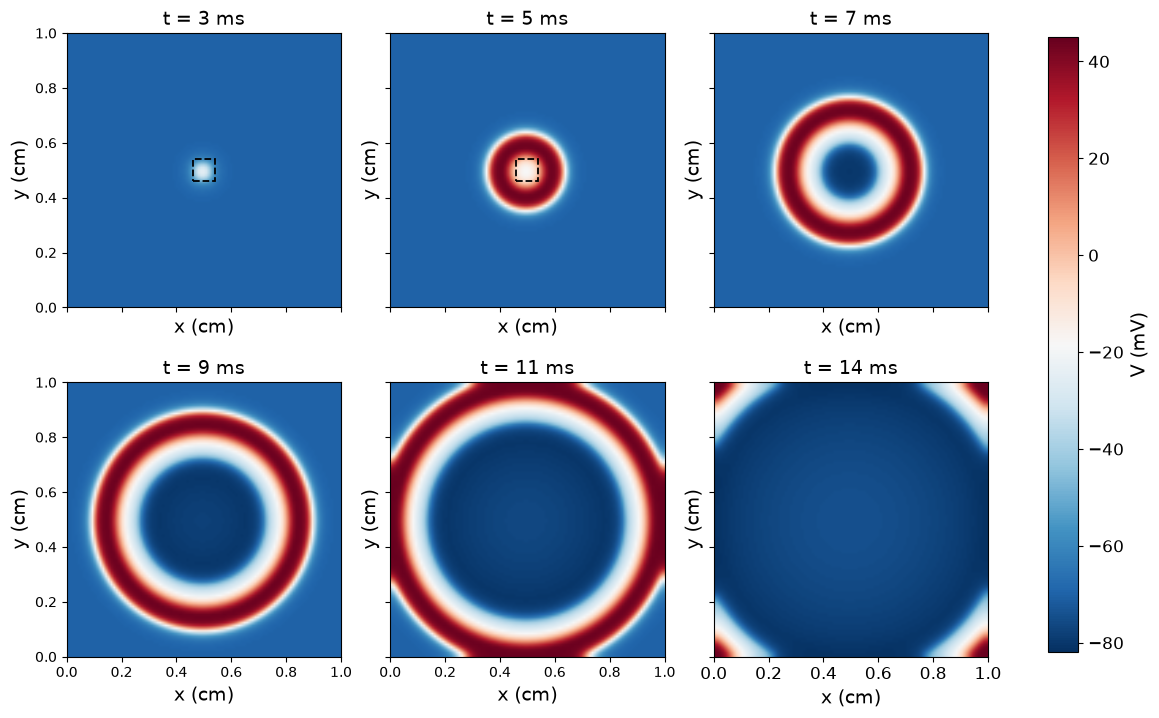

In [14]:
# -----------------------------
# Simulation 2: centered point-like stimulus
# -----------------------------
L2 = 1.0
NX2 = NY2 = 101
T2 = 14.0
STIM_AMP_POINT = 30.0
STIM_START_POINT = 2.0
STIM_END_POINT = 5.0
STIM_SIZE_POINT = 0.08
SNAP_TIMES_POINT = np.array([3.0, 5.0, 7.0, 9.0, 11.0, 14.0])

@njit(cache=False)
def run_point_stimulus():
    dx = L2 / (NX2 - 1)
    nt = int(round(T2 / DT)) + 1
    km = int(round(TAU_M / DT))
    kh = int(round(TAU_H / DT))
    kk = int(round(TAU_K / DT))
    max_delay = max(km, kh, kk)
    buffer_length = max_delay + 1

    V = np.full((NY2, NX2), V0, dtype=np.float32)
    Vnew = np.empty_like(V)
    history = np.full((buffer_length, NY2, NX2), V0, dtype=np.float32)

    snapshots = np.empty((SNAP_TIMES_POINT.size, NY2, NX2), dtype=np.float32)
    snapshot_indices = np.empty(SNAP_TIMES_POINT.size, dtype=np.int64)
    for s in range(SNAP_TIMES_POINT.size):
        snapshot_indices[s] = int(round(SNAP_TIMES_POINT[s] / DT))

    stim_start_index = int(round(STIM_START_POINT / DT))
    stim_end_index = int(round(STIM_END_POINT / DT))
    centre = 0.5 * L2
    half_size = 0.5 * STIM_SIZE_POINT
    inv_dx2 = 1.0 / (dx * dx)
    next_snapshot = 0

    for i in range(nt):
        history[i % buffer_length, :, :] = V

        if next_snapshot < SNAP_TIMES_POINT.size and i == snapshot_indices[next_snapshot]:
            snapshots[next_snapshot, :, :] = V
            next_snapshot += 1

        if i == nt - 1:
            break

        slot_m = (i - km) % buffer_length
        slot_h = (i - kh) % buffer_length
        slot_k = (i - kk) % buffer_length

        for j in range(NY2):
            down = j - 1 if j > 0 else j
            up = j + 1 if j < NY2 - 1 else j
            y_here = j * dx

            for p in range(NX2):
                left = p - 1 if p > 0 else p
                right = p + 1 if p < NX2 - 1 else p
                x_here = p * dx

                Vm = history[slot_m, j, p] if i >= km else V0
                Vh = history[slot_h, j, p] if i >= kh else V0
                Vk_delayed = history[slot_k, j, p] if i >= kk else V0

                m = max(Vm - VTH, 0.0)
                n = max(Vk_delayed - VTH, 0.0)
                h = max(VMAX - max(Vh, VTH), 0.0)  # nested maximum

                GNa = GNAB + CNA * m * h
                GK = GKB + CK * n
                v = V[j, p]
                Iion = GK * (v - VK) + GNa * (v - VNA)

                lap = (V[j, right] - 2.0 * v + V[j, left]
                       + V[up, p] - 2.0 * v + V[down, p]) * inv_dx2

                inside_patch = (abs(x_here - centre) <= half_size
                                and abs(y_here - centre) <= half_size)
                Iext = STIM_AMP_POINT if (stim_start_index < i < stim_end_index
                                           and inside_patch) else 0.0
                Vnew[j, p] = v + DT * ((-Iion + Iext) / CM + D * lap)

        V, Vnew = Vnew, V

    return snapshots

snapshots_point = run_point_stimulus()

fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.2), sharex=True, sharey=True,
                         constrained_layout=True)
axes = axes.ravel()

for panel, (ax, Vpanel, tt) in enumerate(zip(axes, snapshots_point, SNAP_TIMES_POINT)):
    im = ax.imshow(Vpanel, origin="lower", extent=[0, L2, 0, L2],
                   cmap="RdBu_r", vmin=-82, vmax=45, interpolation="bilinear")
    if tt <= STIM_END_POINT:
        ax.add_patch(Rectangle((0.5 * L2 - 0.5 * STIM_SIZE_POINT,
                                0.5 * L2 - 0.5 * STIM_SIZE_POINT),
                               STIM_SIZE_POINT, STIM_SIZE_POINT,
                               fill=False, ls="--", lw=1.3, edgecolor="black"))
    ax.set_title(f"t = {tt:g} ms", fontsize=14)
    ax.set_xlabel("x (cm)", fontsize=14)
    ax.set_ylabel("y (cm)", fontsize=14)
    plt.tick_params(labelsize=12)

cbar = fig.colorbar(im, ax=axes.tolist(), shrink=0.9, label="V (mV)")

cbar.set_label("V (mV)", size=14)

cbar.ax.tick_params(labelsize=12)
fig.savefig(FIGDIR / "point_stimulus.png", dpi=220, bbox_inches="tight")
plt.show()

# Fig. 2.10: Three outcomes of S1–S2

Running Complete block (S1-S2 = 4.0 ms)...
Running Spiral formation (S1-S2 = 6.0 ms)...
Running Successful propagation (S1-S2 = 8.0 ms)...


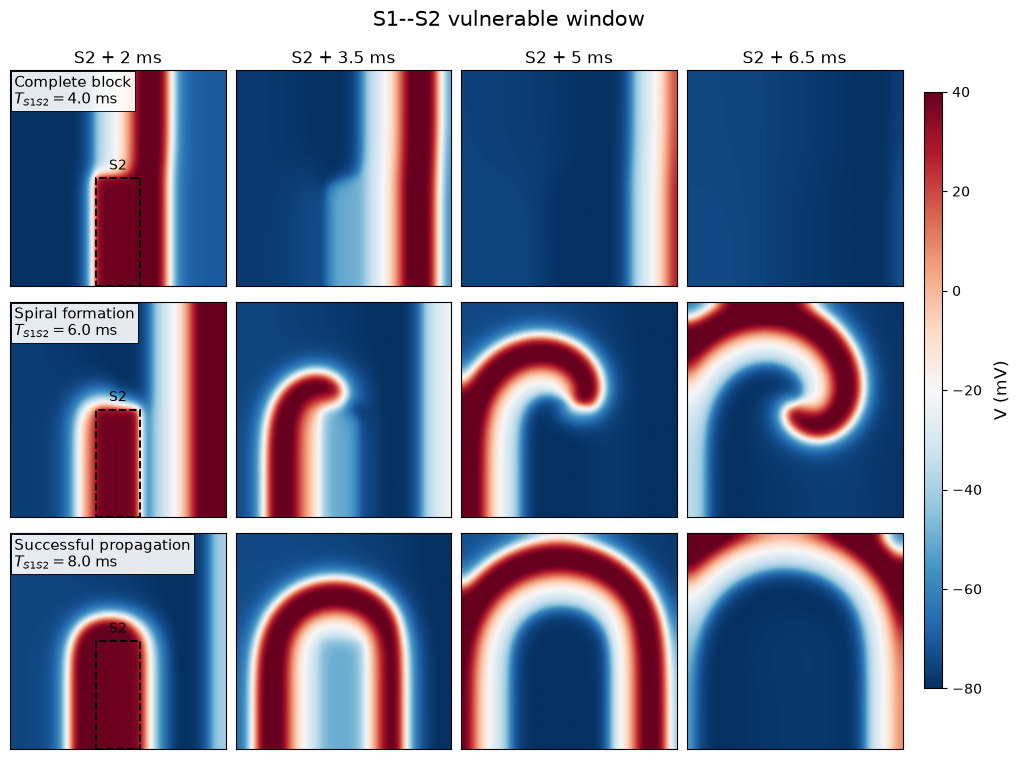

Figure saved to: figures_chapter1/vulnerable_window_3x4_clean.png

Complete block          T_S1S2 = 4.0 ms
  snapshots = 6.0 ms, 7.5 ms, 9.0 ms, 10.5 ms
Spiral formation        T_S1S2 = 6.0 ms
  snapshots = 8.0 ms, 9.5 ms, 11.0 ms, 12.5 ms
Successful propagation  T_S1S2 = 8.0 ms
  snapshots = 10.0 ms, 11.5 ms, 13.0 ms, 14.5 ms


In [15]:
# ============================================================
# Vulnerable window in 2D:
# complete block, spiral initiation, and successful propagation
#
# 3 x 4 snapshot figure
#
# Columns:
#   S2 + 2 ms
#   S2 + 3.5 ms
#   S2 + 5 ms
#   S2 + 6.5 ms
#
# Rows:
#   Complete block
#   Spiral formation
#   Successful propagation
# ============================================================

import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from numba import njit


# ============================================================
# Output directory
# ============================================================

try:
    FIGDIR
except NameError:
    FIGDIR = Path("figures_chapter1")

FIGDIR.mkdir(
    exist_ok=True
)


# ============================================================
# Check base model variables
# ============================================================

required_variables = [
    "DT",
    "SIGMA",
    "CHI",
    "CM",
    "V0",
    "VTH",
    "VMAX",
    "GNAB",
    "CNA",
    "CK",
    "GKB",
    "VK",
    "VNA",
    "TAU_M",
    "TAU_H",
    "TAU_K"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"{variable_name} was not found. "
            "Run the base membrane/cable model first."
        )


# ============================================================
# Tissue and protocol
# ============================================================

L_VW = 0.5

NX_VW = 131
NY_VW = 131

# Last required snapshot:
# 8.0 + 6.5 = 14.5 ms
T_VW = 15.0


# ============================================================
# S1 planar wave
# ============================================================

S1_AMP_VW = 30.0
S1_END_VW = 0.5

S1_WIDTH_VW = (
    0.12 * L_VW
)


# ============================================================
# S2 rectangular region
# ============================================================

S2_XA_VW = 0.20
S2_XB_VW = 0.30

S2_YA_VW = 0.00
S2_YB_VW = 0.25


# ============================================================
# Duration of prescribed local S2 AP
# ============================================================

S2_PHASE_VW = 1.77


# ============================================================
# S1--S2 cases
# ============================================================

CASE_DATA = [
    (
        "Complete block",
        4.0
    ),

    (
        "Spiral formation",
        6.0
    ),

    (
        "Successful propagation",
        8.0
    )
]


# ============================================================
# Snapshot times relative to S2
# ============================================================

RELATIVE_SNAPSHOT_TIMES_VW = np.array([
    2.0,
    3.5,
    5.0,
    6.5
])


# ============================================================
# Voltage color scale
# ============================================================

VMIN_VW = -80.0
VMAX_VW = 40.0


# ============================================================
# 0D action potential
# ============================================================

@njit(cache=False)
def simulate_zero_dimensional_ap_vw(
    total_time,
    stimulus_amplitude,
    stimulus_end
):

    nt = (
        int(
            round(
                total_time / DT
            )
        )
        + 1
    )

    V = np.full(
        nt,
        V0,
        dtype=np.float64
    )


    km = int(
        round(
            TAU_M / DT
        )
    )

    kh = int(
        round(
            TAU_H / DT
        )
    )

    kk = int(
        round(
            TAU_K / DT
        )
    )


    for i in range(
        nt - 1
    ):

        Vm = (
            V[i - km]
            if i >= km
            else V0
        )

        Vh = (
            V[i - kh]
            if i >= kh
            else V0
        )

        Vk_delayed = (
            V[i - kk]
            if i >= kk
            else V0
        )


        m = max(
            Vm - VTH,
            0.0
        )

        n = max(
            Vk_delayed - VTH,
            0.0
        )

        h = max(
            VMAX
            - max(Vh, VTH),
            0.0
        )


        GNa = (
            GNAB
            + CNA * m * h
        )

        GK = (
            GKB
            + CK * n
        )


        Iion = (
            GK * (V[i] - VK)
            + GNa * (V[i] - VNA)
        )


        Iext = (
            stimulus_amplitude
            if i * DT < stimulus_end
            else 0.0
        )


        V[i + 1] = (
            V[i]
            + DT
            * (
                (-Iion + Iext)
                / CM
            )
        )


    return V


# ============================================================
# Interpolation of prescribed AP
# ============================================================

@njit(cache=False)
def interpolate_trace_vw(
    trace,
    time_ms
):

    if time_ms <= 0.0:

        return trace[0]


    position = (
        time_ms / DT
    )

    i0 = int(
        math.floor(position)
    )


    if (
        i0 >= trace.size - 1
    ):

        return trace[-1]


    frac = (
        position
        - i0
    )


    return (
        (1.0 - frac)
        * trace[i0]
        +
        frac
        * trace[i0 + 1]
    )


# ============================================================
# 2D S1--S2 simulation
# ============================================================

@njit(cache=False)
def run_vulnerable_window_case(
    s2_start
):

    # --------------------------------------------------------
    # Spatial discretization
    # --------------------------------------------------------

    dx = (
        L_VW
        / (NX_VW - 1)
    )

    inv_dx2 = (
        1.0
        / (dx * dx)
    )


    # --------------------------------------------------------
    # Time discretization
    # --------------------------------------------------------

    nt = (
        int(
            round(
                T_VW / DT
            )
        )
        + 1
    )


    # --------------------------------------------------------
    # Delay indices
    # --------------------------------------------------------

    km = int(
        round(
            TAU_M / DT
        )
    )

    kh = int(
        round(
            TAU_H / DT
        )
    )

    kk = int(
        round(
            TAU_K / DT
        )
    )


    max_delay = max(
        km,
        kh,
        kk
    )

    buffer_length = (
        max_delay + 1
    )


    # --------------------------------------------------------
    # Diffusion coefficient
    # --------------------------------------------------------

    D_local = (
        SIGMA
        / (CHI * CM)
    )


    # --------------------------------------------------------
    # Initial voltage
    # --------------------------------------------------------

    V = np.full(
        (
            NY_VW,
            NX_VW
        ),
        V0,
        dtype=np.float32
    )

    Vnew = np.empty_like(
        V
    )


    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history = np.full(
        (
            buffer_length,
            NY_VW,
            NX_VW
        ),
        V0,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Snapshot storage
    # --------------------------------------------------------

    n_snapshots = (
        RELATIVE_SNAPSHOT_TIMES_VW.size
    )


    snapshots = np.empty(
        (
            n_snapshots,
            NY_VW,
            NX_VW
        ),
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Absolute snapshot times
    # --------------------------------------------------------

    snapshot_indices = np.empty(
        n_snapshots,
        dtype=np.int64
    )


    for s in range(
        n_snapshots
    ):

        absolute_time = (
            s2_start
            + RELATIVE_SNAPSHOT_TIMES_VW[s]
        )

        snapshot_indices[s] = int(
            round(
                absolute_time / DT
            )
        )


    # --------------------------------------------------------
    # Prescribed S2 AP
    # --------------------------------------------------------

    trace_length = (
        S2_PHASE_VW
        + max(
            TAU_M,
            TAU_H,
            TAU_K
        )
        + 0.5
    )


    prescribed_trace = (
        simulate_zero_dimensional_ap_vw(
            trace_length,
            S1_AMP_VW,
            S1_END_VW
        )
    )


    s2_end = (
        s2_start
        + S2_PHASE_VW
    )


    s1_end_index = int(
        round(
            S1_END_VW / DT
        )
    )


    next_snapshot = 0


    # ========================================================
    # Time integration
    # ========================================================

    for it in range(nt):

        history[
            it % buffer_length,
            :, :
        ] = V


        # ----------------------------------------------------
        # Snapshot
        # ----------------------------------------------------

        if (
            next_snapshot < n_snapshots
            and it == snapshot_indices[
                next_snapshot
            ]
        ):

            snapshots[
                next_snapshot,
                :, :
            ] = V

            next_snapshot += 1


        if it == nt - 1:

            break


        # ----------------------------------------------------
        # Delayed slots
        # ----------------------------------------------------

        slot_m = (
            it - km
        ) % buffer_length

        slot_h = (
            it - kh
        ) % buffer_length

        slot_k = (
            it - kk
        ) % buffer_length


        time_now = (
            it * DT
        )


        # ====================================================
        # Spatial loop
        # ====================================================

        for j in range(
            NY_VW
        ):

            down = (
                j - 1
                if j > 0
                else j
            )

            up = (
                j + 1
                if j < NY_VW - 1
                else j
            )


            y_here = (
                j * dx
            )


            for p in range(
                NX_VW
            ):

                left = (
                    p - 1
                    if p > 0
                    else p
                )

                right = (
                    p + 1
                    if p < NX_VW - 1
                    else p
                )


                x_here = (
                    p * dx
                )


                # ------------------------------------------------
                # S2 rectangle
                # ------------------------------------------------

                in_s2_rect = (
                    S2_XA_VW
                    <= x_here
                    <= S2_XB_VW
                    and
                    S2_YA_VW
                    <= y_here
                    <= S2_YB_VW
                )


                # =================================================
                # Prescribed S2
                # =================================================

                if (
                    in_s2_rect
                    and
                    s2_start
                    <= time_now
                    <= s2_end
                ):

                    local_time = (
                        time_now
                        - s2_start
                    )


                    V_local = (
                        interpolate_trace_vw(
                            prescribed_trace,
                            local_time
                        )
                    )


                    Vnew[
                        j,
                        p
                    ] = V_local


                    if it >= km:

                        history[
                            slot_m,
                            j,
                            p
                        ] = (
                            interpolate_trace_vw(
                                prescribed_trace,
                                local_time
                                - TAU_M
                            )
                        )


                    if it >= kh:

                        history[
                            slot_h,
                            j,
                            p
                        ] = (
                            interpolate_trace_vw(
                                prescribed_trace,
                                local_time
                                - TAU_H
                            )
                        )


                    if it >= kk:

                        history[
                            slot_k,
                            j,
                            p
                        ] = (
                            interpolate_trace_vw(
                                prescribed_trace,
                                local_time
                                - TAU_K
                            )
                        )


                    continue


                # =================================================
                # Delayed variables
                # =================================================

                Vm = (
                    history[
                        slot_m,
                        j,
                        p
                    ]
                    if it >= km
                    else V0
                )


                Vh = (
                    history[
                        slot_h,
                        j,
                        p
                    ]
                    if it >= kh
                    else V0
                )


                Vk_delayed = (
                    history[
                        slot_k,
                        j,
                        p
                    ]
                    if it >= kk
                    else V0
                )


                # ------------------------------------------------
                # Gating variables
                # ------------------------------------------------

                m = max(
                    Vm - VTH,
                    0.0
                )

                n = max(
                    Vk_delayed - VTH,
                    0.0
                )

                h = max(
                    VMAX
                    - max(Vh, VTH),
                    0.0
                )


                # ------------------------------------------------
                # Conductances
                # ------------------------------------------------

                GNa = (
                    GNAB
                    + CNA * m * h
                )

                GK = (
                    GKB
                    + CK * n
                )


                # ------------------------------------------------
                # Ionic current
                # ------------------------------------------------

                v = V[
                    j,
                    p
                ]


                Iion = (
                    GK * (v - VK)
                    + GNa * (v - VNA)
                )


                # ------------------------------------------------
                # 2D Laplacian
                # ------------------------------------------------

                lap = (
                    V[j, right]
                    + V[j, left]
                    + V[up, p]
                    + V[down, p]
                    - 4.0 * v
                ) * inv_dx2


                # ------------------------------------------------
                # S1 stimulus
                # ------------------------------------------------

                Iext = 0.0

                if (
                    x_here <= S1_WIDTH_VW
                    and it < s1_end_index
                ):

                    Iext = (
                        S1_AMP_VW
                    )


                # ------------------------------------------------
                # Voltage update
                # ------------------------------------------------

                Vnew[
                    j,
                    p
                ] = (
                    v
                    + DT
                    * (
                        (-Iion + Iext)
                        / CM
                        + D_local
                        * lap
                    )
                )


        # ----------------------------------------------------
        # Advance
        # ----------------------------------------------------

        V, Vnew = (
            Vnew,
            V
        )


    return snapshots


# ============================================================
# Run the three cases
# ============================================================

all_snapshots = []

for case_name, s2_start in CASE_DATA:

    print(
        f"Running {case_name} "
        f"(S1-S2 = {s2_start:.1f} ms)..."
    )

    snapshots = (
        run_vulnerable_window_case(
            s2_start
        )
    )

    all_snapshots.append(
        snapshots
    )


# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(10.5, 7.8)
)


# ============================================================
# Plot snapshots
# ============================================================

for row, (
    case_name,
    s2_start
) in enumerate(CASE_DATA):

    snapshots = all_snapshots[row]

    for col in range(4):

        ax = axes[row, col]

        # ----------------------------------------------------
        # Voltage field
        # ----------------------------------------------------

        im = ax.imshow(
            snapshots[col],
            origin="lower",
            extent=[
                0.0,
                L_VW,
                0.0,
                L_VW
            ],
            vmin=VMIN_VW,
            vmax=VMAX_VW,
            cmap="RdBu_r",
            interpolation="bilinear",
            aspect="equal"
        )

        # ----------------------------------------------------
        # No ordinary axis ticks
        # ----------------------------------------------------

        ax.set_xticks([])
        ax.set_yticks([])

        # ----------------------------------------------------
        # Column titles
        # ----------------------------------------------------

        if row == 0:

            relative_time = (
                RELATIVE_SNAPSHOT_TIMES_VW[col]
            )

            ax.set_title(
                f"S2 + {relative_time:g} ms",
                fontsize=12,
                pad=5
            )

        # ----------------------------------------------------
        # Row labels
        # ----------------------------------------------------

        if col == 0:

            ax.text(
                0.02,
                0.98,
                (
                    f"{case_name}\n"
                    rf"$T_{{S1S2}} = {s2_start:.1f}$ ms"
                ),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=10.5,
                color="black",
                linespacing=1.15,
                bbox=dict(
                    boxstyle="square,pad=0.22",
                    facecolor="white",
                    edgecolor="black",
                    linewidth=0.7,
                    alpha=0.90
                ),
                zorder=10
            )


# ============================================================
# S2 rectangles
# ============================================================

for row in range(3):

    ax = axes[row, 0]

    rectangle = Rectangle(
        (
            S2_XA_VW,
            S2_YA_VW
        ),
        S2_XB_VW - S2_XA_VW,
        S2_YB_VW - S2_YA_VW,
        fill=False,
        edgecolor="black",
        linestyle="--",
        linewidth=1.4,
        zorder=20
    )

    ax.add_patch(
        rectangle
    )

    # --------------------------------------------------------
    # S2 label
    # --------------------------------------------------------

    ax.text(
        (
            S2_XA_VW
            + S2_XB_VW
        ) / 2.0,
        S2_YB_VW + 0.012,
        "S2",
        ha="center",
        va="bottom",
        fontsize=10,
        color="black",
        zorder=21
    )


# ============================================================
# Main title
# ============================================================

fig.suptitle(
    "S1--S2 vulnerable window",
    fontsize=15,
    y=0.985
)


# ============================================================
# Leave a dedicated region for the colorbar
# ============================================================

fig.subplots_adjust(
    left=0.025,
    right=0.875,      # IMPORTANT: leaves space for colorbar
    bottom=0.035,
    top=0.91,
    wspace=0.045,
    hspace=0.055
)


# ============================================================
# Colorbar
# ============================================================

# Position explicitly so that it cannot overlap the panels
cbar_ax = fig.add_axes([
    0.895,   # left
    0.115,   # bottom
    0.018,   # width
    0.765    # height
])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label(
    "V (mV)",
    fontsize=12,
    labelpad=8
)

cbar.ax.tick_params(
    labelsize=10
)


# ============================================================
# Save
# ============================================================

output_path = (
    FIGDIR
    / "vulnerable_window_3x4_clean.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# Show
# ============================================================

plt.show()


print(
    f"Figure saved to: {output_path}"
)

print()

for case_name, s2_start in CASE_DATA:

    absolute_times = (
        s2_start
        + RELATIVE_SNAPSHOT_TIMES_VW
    )

    print(
        f"{case_name:22s}"
        f"  T_S1S2 = {s2_start:.1f} ms"
    )

    print(
        "  snapshots = "
        +
        ", ".join(
            f"{t:.1f} ms"
            for t in absolute_times
        )
    )

# Fig. 2.11: Snapshots spiral

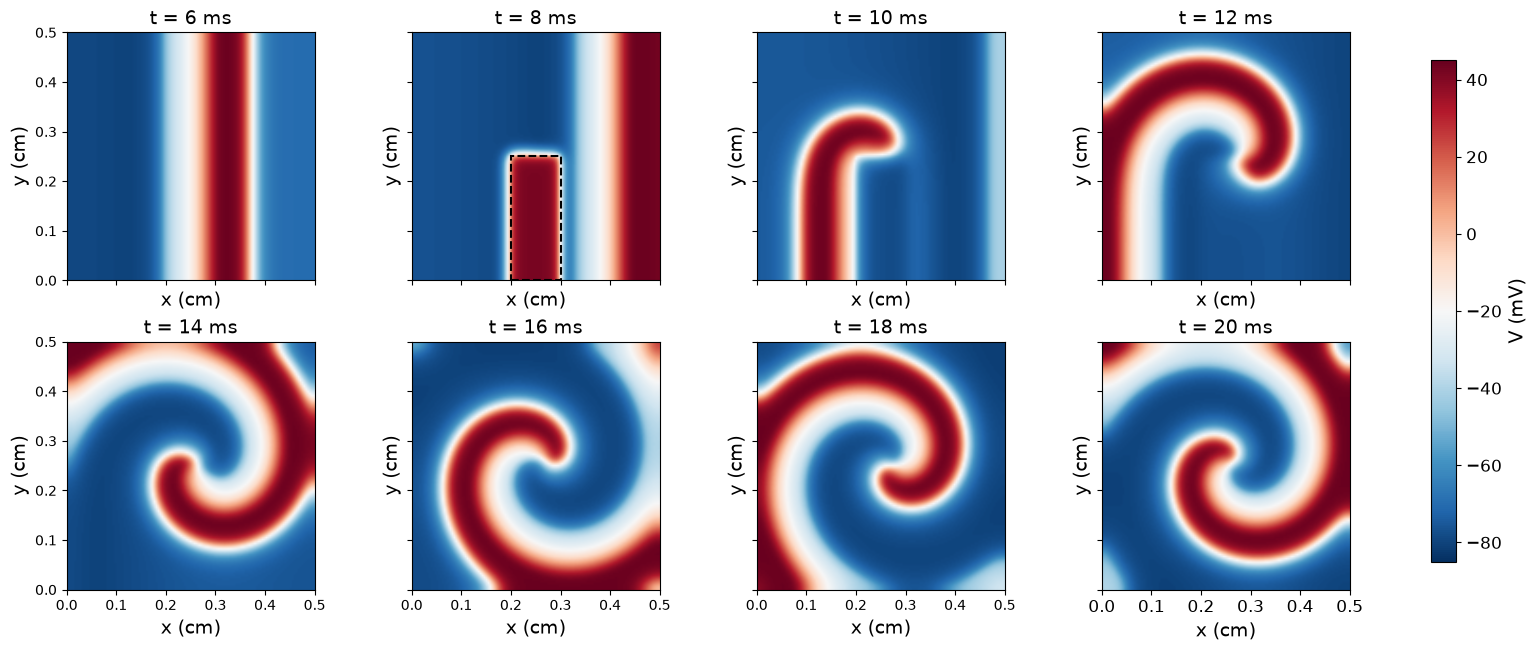

In [16]:
# -----------------------------
# Simulation 3: prescribed-S2 spiral
# -----------------------------
L3 = 0.5
NX3 = NY3 = 131
T3 = 25.0
S1_AMP_SPIRAL = 30.0
S1_END_SPIRAL = 0.5
S1_WIDTH_SPIRAL = 0.12 * L3
S2_START = 7.9
S2_PHASE = 1.77
S2_XA, S2_XB = 0.20, 0.30
S2_YA, S2_YB = 0.00, 0.25
SNAP_TIMES_SPIRAL = np.array([6.0, 8.0, 10.0, 12.0, 14.0,
                              16.0, 18.0, 20.0])

@njit(cache=False)
def simulate_zero_dimensional_ap(total_time, stimulus_amplitude, stimulus_end):
    nt = int(round(total_time / DT)) + 1
    V = np.full(nt, V0, dtype=np.float64)
    km = int(round(TAU_M / DT))
    kh = int(round(TAU_H / DT))
    kk = int(round(TAU_K / DT))

    for i in range(nt - 1):
        Vm = V[i - km] if i >= km else V0
        Vh = V[i - kh] if i >= kh else V0
        Vk_delayed = V[i - kk] if i >= kk else V0

        m = max(Vm - VTH, 0.0)
        n = max(Vk_delayed - VTH, 0.0)
        h = max(VMAX - max(Vh, VTH), 0.0)  # nested maximum

        GNa = GNAB + CNA * m * h
        GK = GKB + CK * n
        Iion = GK * (V[i] - VK) + GNa * (V[i] - VNA)
        Iext = stimulus_amplitude if i * DT < stimulus_end else 0.0
        V[i + 1] = V[i] + DT * ((-Iion + Iext) / CM)

    return V

@njit(cache=False)
def interpolate_trace(trace, time_ms):
    if time_ms <= 0.0:
        return trace[0]
    position = time_ms / DT
    i0 = int(math.floor(position))
    if i0 >= trace.size - 1:
        return trace[-1]
    fraction = position - i0
    return (1.0 - fraction) * trace[i0] + fraction * trace[i0 + 1]

@njit(cache=False)
def run_prescribed_s2_spiral():
    dx = L3 / (NX3 - 1)
    nt = int(round(T3 / DT)) + 1
    km = int(round(TAU_M / DT))
    kh = int(round(TAU_H / DT))
    kk = int(round(TAU_K / DT))
    max_delay = max(km, kh, kk)
    buffer_length = max_delay + 1

    V = np.full((NY3, NX3), V0, dtype=np.float32)
    Vnew = np.empty_like(V)
    history = np.full((buffer_length, NY3, NX3), V0, dtype=np.float32)

    snapshots = np.empty((SNAP_TIMES_SPIRAL.size, NY3, NX3), dtype=np.float32)
    snapshot_indices = np.empty(SNAP_TIMES_SPIRAL.size, dtype=np.int64)
    for s in range(SNAP_TIMES_SPIRAL.size):
        snapshot_indices[s] = int(round(SNAP_TIMES_SPIRAL[s] / DT))

    ap_trace = simulate_zero_dimensional_ap(20.0, S1_AMP_SPIRAL, S1_END_SPIRAL)
    s2_index = int(round(S2_START / DT))
    s1_end_index = int(round(S1_END_SPIRAL / DT))
    inv_dx2 = 1.0 / (dx * dx)
    next_snapshot = 0

    for i in range(nt):
        # At S2, prescribe both V and its complete delayed history in the patch.
        if i == s2_index:
            for delay_index in range(buffer_length):
                prescribed_value = interpolate_trace(ap_trace,
                                                     S2_PHASE - delay_index * DT)
                slot = (i - delay_index) % buffer_length
                for j in range(NY3):
                    y_here = j * dx
                    if y_here < S2_YA or y_here > S2_YB:
                        continue
                    for p in range(NX3):
                        x_here = p * dx
                        if S2_XA <= x_here <= S2_XB:
                            history[slot, j, p] = prescribed_value

            current_patch_value = interpolate_trace(ap_trace, S2_PHASE)
            for j in range(NY3):
                y_here = j * dx
                if y_here < S2_YA or y_here > S2_YB:
                    continue
                for p in range(NX3):
                    x_here = p * dx
                    if S2_XA <= x_here <= S2_XB:
                        V[j, p] = current_patch_value

        history[i % buffer_length, :, :] = V

        if next_snapshot < SNAP_TIMES_SPIRAL.size and i == snapshot_indices[next_snapshot]:
            snapshots[next_snapshot, :, :] = V
            next_snapshot += 1

        if i == nt - 1:
            break

        slot_m = (i - km) % buffer_length
        slot_h = (i - kh) % buffer_length
        slot_k = (i - kk) % buffer_length

        for j in range(NY3):
            down = j - 1 if j > 0 else j
            up = j + 1 if j < NY3 - 1 else j

            for p in range(NX3):
                left = p - 1 if p > 0 else p
                right = p + 1 if p < NX3 - 1 else p

                Vm = history[slot_m, j, p] if i >= km else V0
                Vh = history[slot_h, j, p] if i >= kh else V0
                Vk_delayed = history[slot_k, j, p] if i >= kk else V0

                m = max(Vm - VTH, 0.0)
                n = max(Vk_delayed - VTH, 0.0)
                h = max(VMAX - max(Vh, VTH), 0.0)  # nested maximum

                GNa = GNAB + CNA * m * h
                GK = GKB + CK * n
                v = V[j, p]
                Iion = GK * (v - VK) + GNa * (v - VNA)

                lap = (V[j, right] - 2.0 * v + V[j, left]
                       + V[up, p] - 2.0 * v + V[down, p]) * inv_dx2

                x_here = p * dx
                Iext = S1_AMP_SPIRAL if (i < s1_end_index
                                         and x_here <= S1_WIDTH_SPIRAL) else 0.0
                Vnew[j, p] = v + DT * ((-Iion + Iext) / CM + D * lap)

        V, Vnew = Vnew, V

    return snapshots

snapshots_spiral = run_prescribed_s2_spiral()

fig, axes = plt.subplots(2, 4, figsize=(15.5, 6.4), sharex=True, sharey=True,
                         constrained_layout=True)
axes = axes.ravel()

for ax, Vpanel, tt in zip(axes, snapshots_spiral, SNAP_TIMES_SPIRAL):
    im = ax.imshow(Vpanel, origin="lower", extent=[0, L3, 0, L3],
                   cmap="RdBu_r", vmin=-85, vmax=45, interpolation="bilinear")
    if abs(tt - 8.0) < 1e-12:
        ax.add_patch(Rectangle((S2_XA, S2_YA), S2_XB - S2_XA, S2_YB - S2_YA,
                               fill=False, ls="--", lw=1.5, edgecolor="black"))
    ax.set_title(f"t = {tt:g} ms", fontsize=14)
    ax.set_xlabel("x (cm)", fontsize=14)
    ax.set_ylabel("y (cm)", fontsize=14)
    plt.tick_params(labelsize=12)

cbar = fig.colorbar(im, ax=axes.tolist(), shrink=0.9, label="V (mV)")

cbar.set_label("V (mV)", size=14)

cbar.ax.tick_params(labelsize=12)
fig.savefig(FIGDIR / "spiral_prescribed_s2.png", dpi=220, bbox_inches="tight")
plt.show()

# Fig. 2.12: Bent Scroll

3D grid: 41 x 41 x 37
Delay-history memory: approximately 0.32 GB
Number of voxels in S2 region: 6240
3D S1-S2 simulation completed.


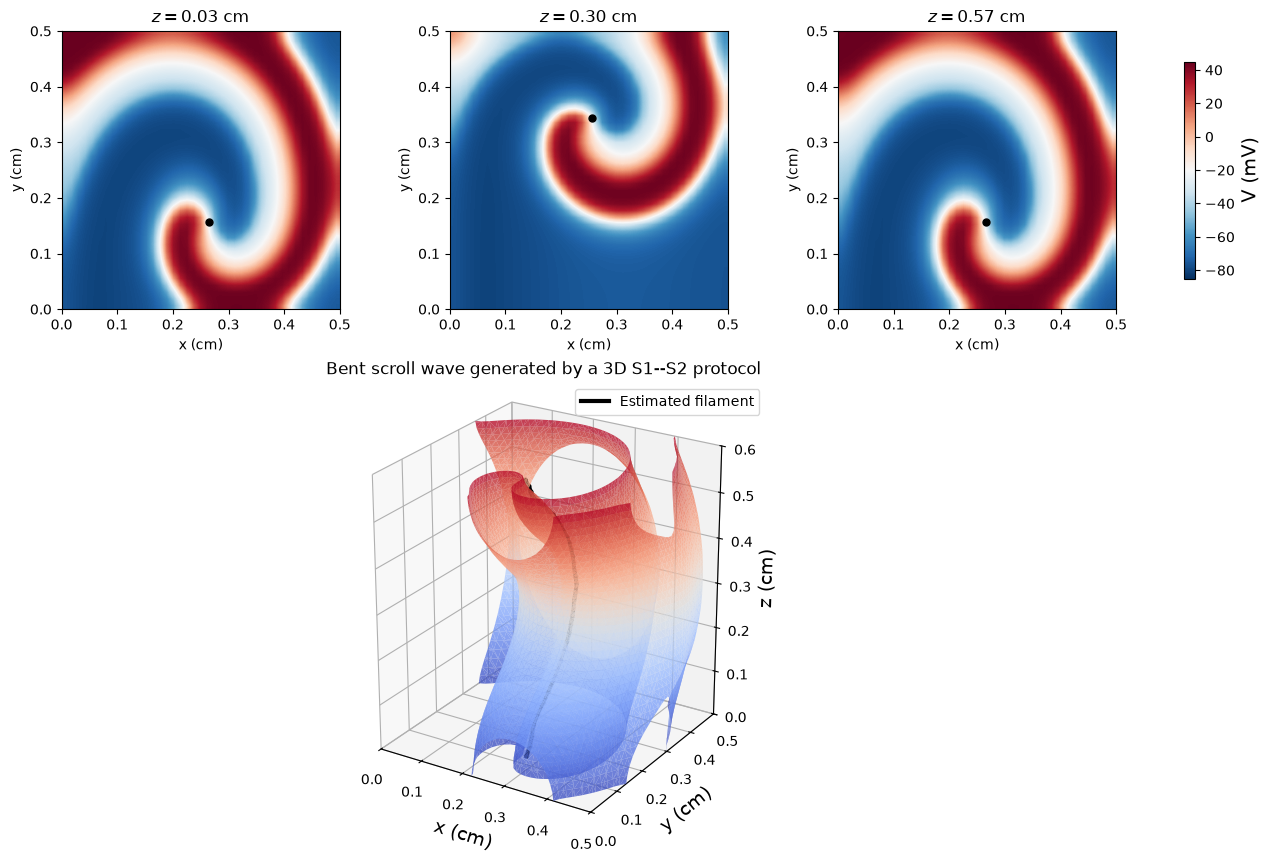

Figure saved to: figures_chapter1/bent_scroll_wave_s1s2.png


In [17]:
# ============================================================
# Bent scroll wave generated by a genuine 3D S1-S2 protocol
# ============================================================

import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange

try:
    from skimage.measure import marching_cubes
except ImportError as exc:
    raise ImportError(
        "This cell requires scikit-image. Install it with:\n"
        "pip install scikit-image"
    ) from exc


# ------------------------------------------------------------
# Check that the membrane-model constants are available
# ------------------------------------------------------------
required_parameters = [
    "CM", "GKB", "GNAB", "CK", "CNA",
    "VK", "VNA", "V0", "VTH", "VMAX",
    "TAU_K", "TAU_M", "TAU_H",
    "SIGMA", "CHI"
]

for parameter_name in required_parameters:
    if parameter_name not in globals():
        raise RuntimeError(
            f"{parameter_name} was not found. "
            "Run the parameter-definition cell first."
        )

try:
    FIGDIR
except NameError:
    FIGDIR = Path("figures_chapter1")
    FIGDIR.mkdir(exist_ok=True)


# ------------------------------------------------------------
# Three-dimensional domain
# ------------------------------------------------------------
LX_SCROLL = 0.50  # cm
LY_SCROLL = 0.50  # cm
LZ_SCROLL = 0.60  # cm

NX_SCROLL = 41
NY_SCROLL = 41
NZ_SCROLL = 37

# A slightly larger time step keeps the 3D example manageable.
# It remains well below the explicit diffusion stability limit
# for the present mesh.
DT_SCROLL = 0.002  # ms
T_SCROLL = 14.0    # ms

D_SCROLL = SIGMA / (CHI * CM)


# ------------------------------------------------------------
# S1 protocol: planar wave from the left
# ------------------------------------------------------------
S1_AMP_SCROLL = 30.0
S1_END_SCROLL = 0.5
S1_WIDTH_SCROLL = 0.12 * LX_SCROLL


# ------------------------------------------------------------
# Prescribed S2 protocol
# ------------------------------------------------------------
S2_START_SCROLL = 7.90  # ms
S2_PHASE_SCROLL = 1.77  # ms along the isolated-cell AP

S2_XA_SCROLL = 0.20
S2_XB_SCROLL = 0.30

# The upper S2 boundary is deliberately curved in z.
#
# At the two z boundaries, S2 reaches y = 0.10 cm.
# At the middle of the slab, it reaches y = 0.34 cm.
#
# This produces a curved wave-break line and therefore a
# bent initial filament.
S2_Y_END_SCROLL = 0.10
S2_Y_MIDDLE_SCROLL = 0.34


# Times stored for visualization
SAVE_TIMES_SCROLL = np.array([
    8.0,
    10.0,
    12.0,
    13.8,
    14.0
])


# ------------------------------------------------------------
# Coordinates and curved S2 mask
# ------------------------------------------------------------
x_scroll = np.linspace(
    0.0, LX_SCROLL, NX_SCROLL
)

y_scroll = np.linspace(
    0.0, LY_SCROLL, NY_SCROLL
)

z_scroll = np.linspace(
    0.0, LZ_SCROLL, NZ_SCROLL
)

dx_scroll = x_scroll[1] - x_scroll[0]
dy_scroll = y_scroll[1] - y_scroll[0]
dz_scroll = z_scroll[1] - z_scroll[0]


def s2_upper_boundary(z_value):
    """
    Parabolic upper boundary of the prescribed S2 volume.
    """

    scaled_z = (
        2.0 * z_value / LZ_SCROLL - 1.0
    )

    return (
        S2_Y_END_SCROLL
        +
        (
            S2_Y_MIDDLE_SCROLL
            - S2_Y_END_SCROLL
        )
        * (1.0 - scaled_z**2)
    )


s2_mask_scroll = np.zeros(
    (
        NZ_SCROLL,
        NY_SCROLL,
        NX_SCROLL
    ),
    dtype=np.bool_
)

for k, z_value in enumerate(z_scroll):

    y_upper = s2_upper_boundary(z_value)

    for j, y_value in enumerate(y_scroll):

        if y_value > y_upper:
            continue

        for p, x_value in enumerate(x_scroll):

            if (
                S2_XA_SCROLL
                <= x_value
                <= S2_XB_SCROLL
            ):
                s2_mask_scroll[k, j, p] = True


# Store only the coordinates inside S2.
# This makes the history prescription much faster.
s2_k, s2_j, s2_p = np.nonzero(
    s2_mask_scroll
)

s2_k = s2_k.astype(np.int64)
s2_j = s2_j.astype(np.int64)
s2_p = s2_p.astype(np.int64)


# ------------------------------------------------------------
# Approximate memory use
# ------------------------------------------------------------
maximum_delay_steps = int(
    round(
        max(TAU_M, TAU_H, TAU_K)
        / DT_SCROLL
    )
)

history_length_scroll = maximum_delay_steps + 1

history_memory_gb = (
    history_length_scroll
    * NZ_SCROLL
    * NY_SCROLL
    * NX_SCROLL
    * np.dtype(np.float32).itemsize
    / 1024**3
)

print(
    f"3D grid: "
    f"{NX_SCROLL} x {NY_SCROLL} x {NZ_SCROLL}"
)

print(
    f"Delay-history memory: "
    f"approximately {history_memory_gb:.2f} GB"
)

print(
    f"Number of voxels in S2 region: "
    f"{s2_k.size}"
)


# ------------------------------------------------------------
# Isolated-cell trace used for prescribed S2
# ------------------------------------------------------------
@njit(cache=False)
def simulate_zero_dimensional_ap_scroll(
    total_time,
    stimulus_amplitude,
    stimulus_end
):
    nt = int(
        round(total_time / DT_SCROLL)
    ) + 1

    voltage = np.full(
        nt,
        V0,
        dtype=np.float64
    )

    km = int(round(TAU_M / DT_SCROLL))
    kh = int(round(TAU_H / DT_SCROLL))
    kk = int(round(TAU_K / DT_SCROLL))

    for i in range(nt - 1):

        Vm = (
            voltage[i - km]
            if i >= km else V0
        )

        Vh = (
            voltage[i - kh]
            if i >= kh else V0
        )

        Vk_delayed = (
            voltage[i - kk]
            if i >= kk else V0
        )

        m = max(Vm - VTH, 0.0)
        n = max(Vk_delayed - VTH, 0.0)

        h = max(
            VMAX - max(Vh, VTH),
            0.0
        )

        GNa = GNAB + CNA * m * h
        GK = GKB + CK * n

        ionic_current = (
            GK * (voltage[i] - VK)
            +
            GNa * (voltage[i] - VNA)
        )

        external_current = (
            stimulus_amplitude
            if i * DT_SCROLL < stimulus_end
            else 0.0
        )

        voltage[i + 1] = (
            voltage[i]
            +
            DT_SCROLL
            * (
                -ionic_current
                + external_current
            )
            / CM
        )

    return voltage


@njit(cache=False)
def interpolate_trace_scroll(
    trace,
    time_ms
):
    if time_ms <= 0.0:
        return trace[0]

    position = time_ms / DT_SCROLL
    i0 = int(math.floor(position))

    if i0 >= trace.size - 1:
        return trace[-1]

    fraction = position - i0

    return (
        (1.0 - fraction) * trace[i0]
        +
        fraction * trace[i0 + 1]
    )


# ------------------------------------------------------------
# Full 3D monodomain simulation
# ------------------------------------------------------------
@njit(
    parallel=True,
    fastmath=True,
    cache=False
)
def run_bent_scroll_s1s2(
    s2_k_indices,
    s2_j_indices,
    s2_p_indices
):
    dx = LX_SCROLL / (NX_SCROLL - 1)
    dy = LY_SCROLL / (NY_SCROLL - 1)
    dz = LZ_SCROLL / (NZ_SCROLL - 1)

    inverse_dx2 = 1.0 / (dx * dx)
    inverse_dy2 = 1.0 / (dy * dy)
    inverse_dz2 = 1.0 / (dz * dz)

    nt = int(
        round(T_SCROLL / DT_SCROLL)
    ) + 1

    km = int(round(TAU_M / DT_SCROLL))
    kh = int(round(TAU_H / DT_SCROLL))
    kk = int(round(TAU_K / DT_SCROLL))

    maximum_delay = max(km, kh, kk)
    buffer_length = maximum_delay + 1

    voltage = np.full(
        (
            NZ_SCROLL,
            NY_SCROLL,
            NX_SCROLL
        ),
        V0,
        dtype=np.float32
    )

    voltage_new = np.empty_like(voltage)

    history = np.full(
        (
            buffer_length,
            NZ_SCROLL,
            NY_SCROLL,
            NX_SCROLL
        ),
        V0,
        dtype=np.float32
    )

    snapshots = np.empty(
        (
            SAVE_TIMES_SCROLL.size,
            NZ_SCROLL,
            NY_SCROLL,
            NX_SCROLL
        ),
        dtype=np.float32
    )

    snapshot_indices = np.empty(
        SAVE_TIMES_SCROLL.size,
        dtype=np.int64
    )

    for s in range(
        SAVE_TIMES_SCROLL.size
    ):
        snapshot_indices[s] = int(
            round(
                SAVE_TIMES_SCROLL[s]
                / DT_SCROLL
            )
        )

    ap_trace = (
        simulate_zero_dimensional_ap_scroll(
            20.0,
            S1_AMP_SCROLL,
            S1_END_SCROLL
        )
    )

    s1_end_index = int(
        round(
            S1_END_SCROLL
            / DT_SCROLL
        )
    )

    s2_index = int(
        round(
            S2_START_SCROLL
            / DT_SCROLL
        )
    )

    number_of_s2_voxels = (
        s2_k_indices.size
    )

    next_snapshot = 0

    for i in range(nt):

        # ----------------------------------------------------
        # Prescribe S2 once, including its delayed history
        # ----------------------------------------------------
        if i == s2_index:

            for delay_index in range(
                buffer_length
            ):
                prescribed_value = (
                    interpolate_trace_scroll(
                        ap_trace,
                        S2_PHASE_SCROLL
                        -
                        delay_index
                        * DT_SCROLL
                    )
                )

                history_slot = (
                    i - delay_index
                ) % buffer_length

                for q in range(
                    number_of_s2_voxels
                ):
                    k = s2_k_indices[q]
                    j = s2_j_indices[q]
                    p = s2_p_indices[q]

                    history[
                        history_slot,
                        k,
                        j,
                        p
                    ] = prescribed_value

            current_value = (
                interpolate_trace_scroll(
                    ap_trace,
                    S2_PHASE_SCROLL
                )
            )

            for q in range(
                number_of_s2_voxels
            ):
                k = s2_k_indices[q]
                j = s2_j_indices[q]
                p = s2_p_indices[q]

                voltage[k, j, p] = (
                    current_value
                )

        # Store the current voltage in the delay buffer
        history[
            i % buffer_length,
            :,
            :,
            :
        ] = voltage

        # Save selected volumes
        if (
            next_snapshot
            < SAVE_TIMES_SCROLL.size
            and
            i
            == snapshot_indices[next_snapshot]
        ):
            snapshots[
                next_snapshot,
                :,
                :,
                :
            ] = voltage

            next_snapshot += 1

        if i == nt - 1:
            break

        slot_m = (
            i - km
        ) % buffer_length

        slot_h = (
            i - kh
        ) % buffer_length

        slot_k = (
            i - kk
        ) % buffer_length

        # Parallelize over all y-z rows
        for row in prange(
            NZ_SCROLL * NY_SCROLL
        ):
            k = row // NY_SCROLL
            j = row - k * NY_SCROLL

            k_minus = (
                k - 1 if k > 0 else k
            )

            k_plus = (
                k + 1
                if k < NZ_SCROLL - 1
                else k
            )

            j_minus = (
                j - 1 if j > 0 else j
            )

            j_plus = (
                j + 1
                if j < NY_SCROLL - 1
                else j
            )

            for p in range(NX_SCROLL):

                p_minus = (
                    p - 1 if p > 0 else p
                )

                p_plus = (
                    p + 1
                    if p < NX_SCROLL - 1
                    else p
                )

                Vm = (
                    history[
                        slot_m,
                        k,
                        j,
                        p
                    ]
                    if i >= km else V0
                )

                Vh = (
                    history[
                        slot_h,
                        k,
                        j,
                        p
                    ]
                    if i >= kh else V0
                )

                Vk_delayed = (
                    history[
                        slot_k,
                        k,
                        j,
                        p
                    ]
                    if i >= kk else V0
                )

                m = max(Vm - VTH, 0.0)
                n = max(
                    Vk_delayed - VTH,
                    0.0
                )

                h = max(
                    VMAX - max(Vh, VTH),
                    0.0
                )

                GNa = GNAB + CNA * m * h
                GK = GKB + CK * n

                v = voltage[k, j, p]

                ionic_current = (
                    GK * (v - VK)
                    +
                    GNa * (v - VNA)
                )

                laplacian = (
                    (
                        voltage[k, j, p_plus]
                        - 2.0 * v
                        + voltage[k, j, p_minus]
                    )
                    * inverse_dx2
                    +
                    (
                        voltage[k, j_plus, p]
                        - 2.0 * v
                        + voltage[k, j_minus, p]
                    )
                    * inverse_dy2
                    +
                    (
                        voltage[k_plus, j, p]
                        - 2.0 * v
                        + voltage[k_minus, j, p]
                    )
                    * inverse_dz2
                )

                x_value = p * dx

                external_current = 0.0

                if (
                    i < s1_end_index
                    and
                    x_value
                    <= S1_WIDTH_SCROLL
                ):
                    external_current = (
                        S1_AMP_SCROLL
                    )

                voltage_new[k, j, p] = (
                    v
                    +
                    DT_SCROLL
                    * (
                        (
                            -ionic_current
                            + external_current
                        )
                        / CM
                        +
                        D_SCROLL * laplacian
                    )
                )

        voltage, voltage_new = (
            voltage_new,
            voltage
        )

    return snapshots


# ------------------------------------------------------------
# Run the simulation
# ------------------------------------------------------------
snapshots_bent_scroll = (
    run_bent_scroll_s1s2(
        s2_k,
        s2_j,
        s2_p
    )
)

print("3D S1-S2 simulation completed.")


# ============================================================
# Estimate the filament from phase singularities
# ============================================================

# Use two nearby volumes to estimate dV/dt
V_phase_old = (
    snapshots_bent_scroll[-2]
    .astype(np.float64)
)

V_phase_now = (
    snapshots_bent_scroll[-1]
    .astype(np.float64)
)

phase_time_difference = (
    SAVE_TIMES_SCROLL[-1]
    - SAVE_TIMES_SCROLL[-2]
)

dVdt_phase = (
    V_phase_now - V_phase_old
) / phase_time_difference


def wrap_phase_difference(angle):
    return (
        angle + np.pi
    ) % (2.0 * np.pi) - np.pi


def phase_candidates_in_slice(
    voltage_slice,
    derivative_slice
):
    derivative_scale = np.percentile(
        np.abs(derivative_slice),
        90.0
    )

    derivative_scale = max(
        derivative_scale,
        1.0e-8
    )

    phase = np.arctan2(
        derivative_slice
        / derivative_scale,
        (
            voltage_slice + 20.0
        )
        / 35.0
    )

    top = wrap_phase_difference(
        phase[:-1, 1:]
        - phase[:-1, :-1]
    )

    right = wrap_phase_difference(
        phase[1:, 1:]
        - phase[:-1, 1:]
    )

    bottom = wrap_phase_difference(
        phase[1:, :-1]
        - phase[1:, 1:]
    )

    left = wrap_phase_difference(
        phase[:-1, :-1]
        - phase[1:, :-1]
    )

    winding = (
        top + right + bottom + left
    )

    indices = np.argwhere(
        np.abs(winding) > np.pi
    )

    if indices.size == 0:
        return np.empty((0, 2))

    candidate_y = (
        indices[:, 0] + 0.5
    ) * dy_scroll

    candidate_x = (
        indices[:, 1] + 0.5
    ) * dx_scroll

    return np.column_stack(
        (candidate_x, candidate_y)
    )


candidate_sets = []

for k in range(NZ_SCROLL):
    candidate_sets.append(
        phase_candidates_in_slice(
            V_phase_now[k],
            dVdt_phase[k]
        )
    )


# Track one continuous singularity from the middle slice
filament_x = np.full(
    NZ_SCROLL,
    np.nan
)

filament_y = np.full(
    NZ_SCROLL,
    np.nan
)

middle_k = NZ_SCROLL // 2

middle_candidates = (
    candidate_sets[middle_k]
)

if middle_candidates.shape[0] == 0:
    raise RuntimeError(
        "No phase singularity was found in the "
        "middle slice. Try changing S2_START_SCROLL "
        "by approximately 0.1--0.3 ms."
    )

domain_centre = np.array([
    0.5 * LX_SCROLL,
    0.5 * LY_SCROLL
])

middle_choice = np.argmin(
    np.sum(
        (
            middle_candidates
            - domain_centre
        ) ** 2,
        axis=1
    )
)

filament_x[middle_k] = (
    middle_candidates[middle_choice, 0]
)

filament_y[middle_k] = (
    middle_candidates[middle_choice, 1]
)


# Track toward increasing z
for k in range(
    middle_k + 1,
    NZ_SCROLL
):
    candidates = candidate_sets[k]

    if candidates.shape[0] == 0:
        filament_x[k] = filament_x[k - 1]
        filament_y[k] = filament_y[k - 1]
        continue

    previous_point = np.array([
        filament_x[k - 1],
        filament_y[k - 1]
    ])

    selected = np.argmin(
        np.sum(
            (
                candidates
                - previous_point
            ) ** 2,
            axis=1
        )
    )

    filament_x[k] = candidates[selected, 0]
    filament_y[k] = candidates[selected, 1]


# Track toward decreasing z
for k in range(
    middle_k - 1,
    -1,
    -1
):
    candidates = candidate_sets[k]

    if candidates.shape[0] == 0:
        filament_x[k] = filament_x[k + 1]
        filament_y[k] = filament_y[k + 1]
        continue

    previous_point = np.array([
        filament_x[k + 1],
        filament_y[k + 1]
    ])

    selected = np.argmin(
        np.sum(
            (
                candidates
                - previous_point
            ) ** 2,
            axis=1
        )
    )

    filament_x[k] = candidates[selected, 0]
    filament_y[k] = candidates[selected, 1]


# Mild smoothing for visualization
filament_x_smooth = filament_x.copy()
filament_y_smooth = filament_y.copy()

filament_x_smooth[1:-1] = (
    filament_x[:-2]
    + 2.0 * filament_x[1:-1]
    + filament_x[2:]
) / 4.0

filament_y_smooth[1:-1] = (
    filament_y[:-2]
    + 2.0 * filament_y[1:-1]
    + filament_y[2:]
) / 4.0


# ============================================================
# Extract the 3D wave surface
# ============================================================
surface_level = 0.0

surface_vertices, surface_faces, _, _ = (
    marching_cubes(
        V_phase_now,
        level=surface_level,
        spacing=(
            dz_scroll,
            dy_scroll,
            dx_scroll
        ),
        allow_degenerate=False
    )
)

# marching_cubes coordinates are ordered as z, y, x
surface_z = surface_vertices[:, 0]
surface_y = surface_vertices[:, 1]
surface_x = surface_vertices[:, 2]


# ============================================================
# Figure
# ============================================================
fig = plt.figure(
    figsize=(13.0, 8.5),
    constrained_layout=True
)

grid = fig.add_gridspec(
    2,
    3,
    height_ratios=[1.0, 1.6]
)

slice_indices = [
    2,
    NZ_SCROLL // 2,
    NZ_SCROLL - 3
]

for column, k in enumerate(
    slice_indices
):
    ax = fig.add_subplot(
        grid[0, column]
    )

    image = ax.imshow(
        V_phase_now[k],
        origin="lower",
        extent=[
            0.0,
            LX_SCROLL,
            0.0,
            LY_SCROLL
        ],
        cmap="RdBu_r",
        vmin=-85.0,
        vmax=45.0,
        interpolation="bilinear"
    )

    ax.plot(
        filament_x_smooth[k],
        filament_y_smooth[k],
        "ko",
        markersize=5
    )

    ax.set_xlabel("x (cm)")
    ax.set_ylabel("y (cm)")

    ax.set_title(
        rf"$z={z_scroll[k]:.2f}$ cm"
    )


ax3d = fig.add_subplot(
    grid[1, :],
    projection="3d"
)

ax3d.plot_trisurf(
    surface_x,
    surface_y,
    surface_z,
    triangles=surface_faces,
    cmap="coolwarm",
    linewidth=0.0,
    alpha=0.78,
    antialiased=True
)

ax3d.plot(
    filament_x_smooth,
    filament_y_smooth,
    z_scroll,
    "k-",
    linewidth=3.0,
    label="Estimated filament"
)

ax3d.scatter(
    filament_x_smooth,
    filament_y_smooth,
    z_scroll,
    s=8,
    c="black"
)

ax3d.set_xlim(
    0.0,
    LX_SCROLL
)

ax3d.set_ylim(
    0.0,
    LY_SCROLL
)

ax3d.set_zlim(
    0.0,
    LZ_SCROLL
)

ax3d.set_xlabel("x (cm)", fontsize=14)
ax3d.set_ylabel("y (cm)", fontsize=14)
ax3d.set_zlabel("z (cm)", fontsize=14)

ax3d.set_box_aspect(
    (
        LX_SCROLL,
        LY_SCROLL,
        LZ_SCROLL
    )
)

ax3d.view_init(
    elev=24,
    azim=-58
)

ax3d.set_title(
    "Bent scroll wave generated by a 3D S1--S2 protocol"
)

ax3d.legend()

colorbar = fig.colorbar(
    image,
    ax=fig.axes[:3],
    shrink=0.78,
    location="right"
)

colorbar.set_label("V (mV)", fontsize=14)

output_path = (
    FIGDIR
    / "bent_scroll_wave_s1s2.png"
)

fig.savefig(
    output_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {output_path}")

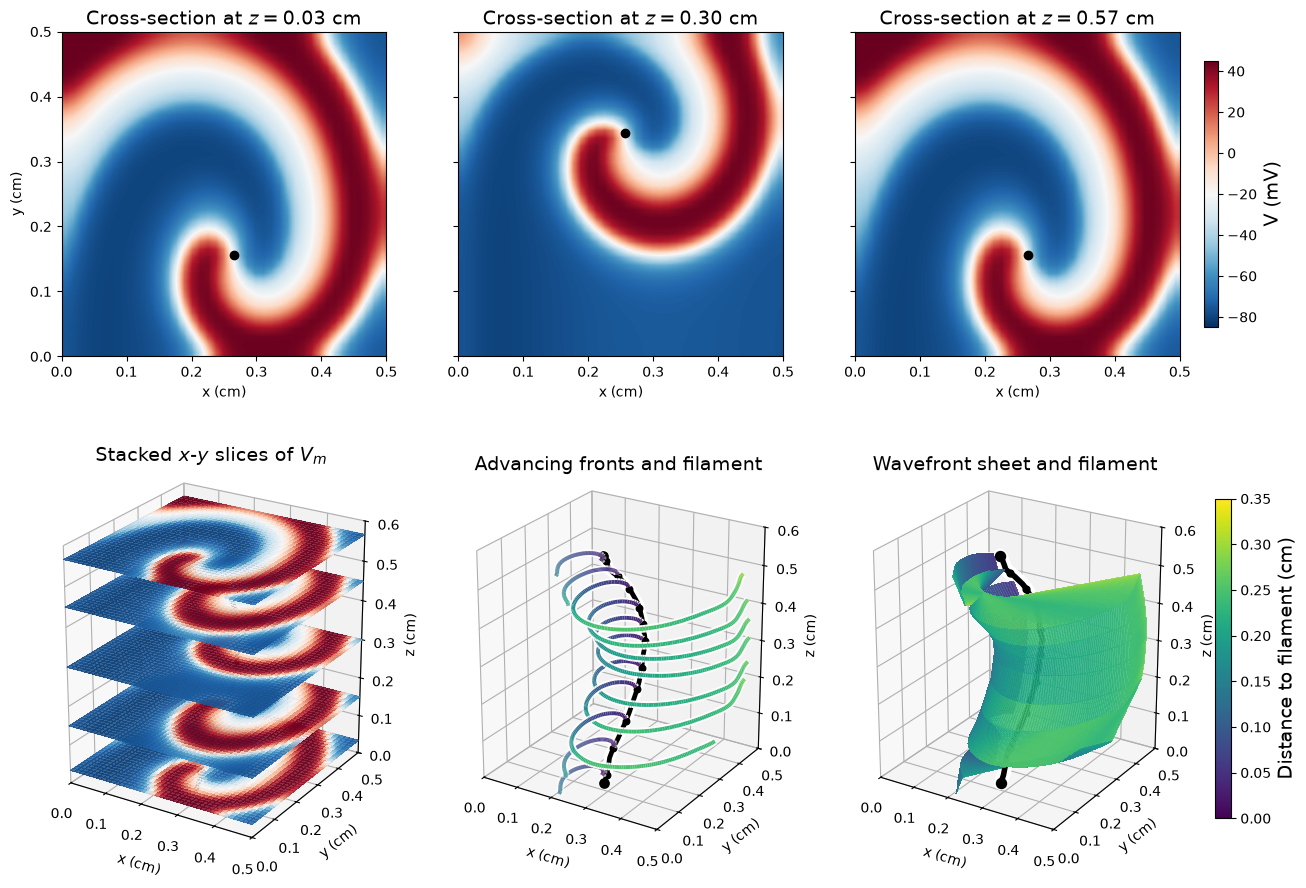

In [18]:
# ============================================================
# Final plotting cell with:
# - top row: 3 x-y cross-sections
# - bottom left: stacked x-y slices of Vm
# - bottom middle: advancing fronts colored by distance
# - bottom right: wavefront sheet with visible filament
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib import cm, colors
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from skimage.measure import find_contours

# ------------------------------------------------------------
# Check required variables
# ------------------------------------------------------------
required_variables = [
    "V_phase_now",
    "dVdt_phase",
    "filament_x_smooth",
    "filament_y_smooth",
    "z_scroll",
    "x_scroll",
    "y_scroll",
    "LX_SCROLL",
    "LY_SCROLL",
    "LZ_SCROLL",
    "NX_SCROLL",
    "NY_SCROLL",
    "NZ_SCROLL",
    "dx_scroll",
    "dy_scroll",
    "FIGDIR",
    "SPIKE_THRESHOLD"
]

for variable_name in required_variables:
    if variable_name not in globals():
        raise RuntimeError(
            f"{variable_name} was not found. "
            "Run the 3D S1--S2 simulation and filament-detection code first."
        )

# ------------------------------------------------------------
# Common viewing angle for ALL bottom 3D panels
# ------------------------------------------------------------
BOTTOM_ELEV = 24
BOTTOM_AZIM = -58

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def format_3d_axis(ax):
    ax.set_xlim(0.0, LX_SCROLL)
    ax.set_ylim(0.0, LY_SCROLL)
    ax.set_zlim(0.0, LZ_SCROLL)

    ax.set_xlabel("x (cm)")
    ax.set_ylabel("y (cm)")
    ax.set_zlabel("z (cm)")

    ax.set_box_aspect((LX_SCROLL, LY_SCROLL, LZ_SCROLL))


def draw_filament(ax, show_points=True, linewidth_center=3.4, linewidth_halo=8.0):
    # white halo
    ax.plot(
        filament_x_smooth,
        filament_y_smooth,
        z_scroll,
        color="white",
        linewidth=linewidth_halo,
        solid_capstyle="round"
    )

    # black center line
    ax.plot(
        filament_x_smooth,
        filament_y_smooth,
        z_scroll,
        color="black",
        linewidth=linewidth_center,
        solid_capstyle="round"
    )

    if show_points:
        ax.scatter(
            filament_x_smooth,
            filament_y_smooth,
            z_scroll,
            color="black",
            s=18,
            depthshade=False
        )


def extract_advancing_front(vertices_xy, k_slice):
    """
    From a contour in the x-y plane, retain the contiguous
    branch corresponding to the advancing front (dV/dt > 0)
    that lies closest to the filament point in this slice.
    """
    if vertices_xy.shape[0] < 8:
        return None, None

    xi = np.clip(
        np.round(vertices_xy[:, 0] / dx_scroll).astype(int),
        0,
        NX_SCROLL - 1
    )

    yi = np.clip(
        np.round(vertices_xy[:, 1] / dy_scroll).astype(int),
        0,
        NY_SCROLL - 1
    )

    local_dvdt = dVdt_phase[k_slice, yi, xi]
    advancing_mask = local_dvdt > 0.0

    if np.count_nonzero(advancing_mask) < 6:
        return None, None

    split_points = np.where(
        np.diff(advancing_mask.astype(int)) != 0
    )[0] + 1

    pieces = np.split(
        np.column_stack([vertices_xy, local_dvdt]),
        split_points
    )

    good_segments = []

    for piece in pieces:
        if piece.shape[0] < 6:
            continue

        if np.mean(piece[:, 2]) <= 0.0:
            continue

        segment_xy = piece[:, :2]

        r = np.sqrt(
            (segment_xy[:, 0] - filament_x_smooth[k_slice])**2
            +
            (segment_xy[:, 1] - filament_y_smooth[k_slice])**2
        )

        good_segments.append((segment_xy, np.min(r), r))

    if len(good_segments) == 0:
        return None, None

    good_segments.sort(key=lambda item: item[1])

    best_xy = good_segments[0][0]
    best_r = good_segments[0][2]

    return best_xy, best_r


def resample_polyline_with_values(points_xy, values, n_samples=140):
    """
    Resample a polyline and associated scalar values by arc length.
    """
    if points_xy.shape[0] < 2:
        return None, None, None

    diffs = np.diff(points_xy, axis=0)
    seglen = np.sqrt(np.sum(diffs**2, axis=1))
    s = np.concatenate([[0.0], np.cumsum(seglen)])

    total_length = s[-1]
    if total_length <= 1.0e-12:
        return None, None, None

    s_uniform = np.linspace(0.0, total_length, n_samples)

    x_uniform = np.interp(s_uniform, s, points_xy[:, 0])
    y_uniform = np.interp(s_uniform, s, points_xy[:, 1])
    v_uniform = np.interp(s_uniform, s, values)

    return x_uniform, y_uniform, v_uniform


# ------------------------------------------------------------
# Slice selections
# ------------------------------------------------------------
slice_indices_top = [
    2,
    NZ_SCROLL // 2,
    NZ_SCROLL - 3
]

slice_indices_stack = [
    2,
    NZ_SCROLL // 4,
    NZ_SCROLL // 2,
    3 * NZ_SCROLL // 4,
    NZ_SCROLL - 3
]

front_slice_indices = np.unique(
    np.linspace(1, NZ_SCROLL - 2, 11, dtype=int)
)

# ------------------------------------------------------------
# Colormaps
# ------------------------------------------------------------

vm_norm = colors.Normalize(vmin=-85.0, vmax=45.0)

# vm_cmap = cm.get_cmap("RdBu_r")
import matplotlib as mpl
vm_cmap     = mpl.colormaps["RdBu_r"]


radius_norm = colors.Normalize(vmin=0.0, vmax=0.35)
# radius_cmap = cm.get_cmap("viridis")
radius_cmap = mpl.colormaps["viridis"]

# Mesh for stacked planes
X_plane, Y_plane = np.meshgrid(x_scroll, y_scroll)

# ------------------------------------------------------------
# Extract and resample advancing fronts
# ------------------------------------------------------------
front_branches = []

for k in front_slice_indices:

    contours_rc = find_contours(
        V_phase_now[k],
        level=SPIKE_THRESHOLD,
        fully_connected="low"
    )

    best_branch = None
    best_radius = None
    best_min_distance = np.inf

    for contour_rc in contours_rc:

        if contour_rc.shape[0] < 8:
            continue

        vertices_xy = np.column_stack([
            contour_rc[:, 1] * dx_scroll,
            contour_rc[:, 0] * dy_scroll
        ])

        branch_xy, branch_r = extract_advancing_front(vertices_xy, k)

        if branch_xy is None:
            continue

        branch_min_distance = np.min(branch_r)

        if branch_min_distance < best_min_distance:
            best_branch = branch_xy
            best_radius = branch_r
            best_min_distance = branch_min_distance

    if best_branch is None or best_branch.shape[0] < 2:
        continue

    x_res, y_res, r_res = resample_polyline_with_values(
        best_branch,
        best_radius,
        n_samples=140
    )

    if x_res is None:
        continue

    # orient branch consistently with previous one
    if len(front_branches) > 0:
        prev = front_branches[-1]
        d_same = (
            np.hypot(x_res[0] - prev["x"][0], y_res[0] - prev["y"][0])
            +
            np.hypot(x_res[-1] - prev["x"][-1], y_res[-1] - prev["y"][-1])
        )
        d_flip = (
            np.hypot(x_res[-1] - prev["x"][0], y_res[-1] - prev["y"][0])
            +
            np.hypot(x_res[0] - prev["x"][-1], y_res[0] - prev["y"][-1])
        )
        if d_flip < d_same:
            x_res = x_res[::-1]
            y_res = y_res[::-1]
            r_res = r_res[::-1]

    front_branches.append({
        "k": k,
        "z": z_scroll[k],
        "x": x_res,
        "y": y_res,
        "r": r_res
    })

if len(front_branches) < 2:
    raise RuntimeError(
        "Not enough advancing fronts were extracted to build the wavefront sheet."
    )

# ------------------------------------------------------------
# Build sheet arrays from resampled fronts
# ------------------------------------------------------------
X_manifold = np.vstack([b["x"] for b in front_branches])
Y_manifold = np.vstack([b["y"] for b in front_branches])
R_manifold = np.vstack([b["r"] for b in front_branches])
Z_manifold = np.vstack([
    np.full_like(b["x"], b["z"]) for b in front_branches
])

# ------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------
# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(figsize=(17.0, 9.5))

grid = fig.add_gridspec(
    2,
    3,
    height_ratios=[1.0, 1.20]
)

fig.subplots_adjust(
    left=0.035,
    right=0.75,
    bottom=0.09,
    top=0.955,
    wspace=0.08,
    hspace=0.3
)


# ============================================================
# Top row: 3 x-y cross-sections
# ============================================================

top_axes = []

for column, k in enumerate(slice_indices_top):

    ax = fig.add_subplot(grid[0, column])

    top_axes.append(ax)

    image = ax.imshow(
        V_phase_now[k],
        origin="lower",
        extent=[
            0.0,
            LX_SCROLL,
            0.0,
            LY_SCROLL
        ],
        cmap="RdBu_r",
        vmin=-85.0,
        vmax=45.0,
        interpolation="bilinear",
        aspect="equal"
    )

    ax.plot(
        filament_x_smooth[k],
        filament_y_smooth[k],
        "ko",
        markersize=6
    )
    ax.set_xlabel("")
    # Only the first panel needs the y-axis label
    if column == 0:
        ax.set_ylabel(
            "y (cm)"
        )
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    # No x-axis label on the top row
    ax.set_xlabel("x (cm)")

    ax.set_title(
        rf"Cross-section at $z={z_scroll[k]:.2f}$ cm",
        fontsize=14,
        pad=5
    )


# ============================================================
# Top colorbar
# ============================================================

colorbar_top = fig.colorbar(
    image,
    ax=top_axes,
    shrink=0.82,
    fraction=0.025,
    pad=0.02
)

colorbar_top.set_label(
    "V (mV)",
    fontsize=14
)


# ============================================================
# Bottom left: stacked x-y slices
# ============================================================

ax_stack = fig.add_subplot(
    grid[1, 0],
    projection="3d"
)

for k in slice_indices_stack:

    Z_plane = np.full_like(
        X_plane,
        z_scroll[k]
    )

    Vm_slice = V_phase_now[k]

    facecolors = vm_cmap(
        vm_norm(Vm_slice)
    )

    ax_stack.plot_surface(
        X_plane,
        Y_plane,
        Z_plane,
        rstride=1,
        cstride=1,
        facecolors=facecolors,
        shade=False,
        linewidth=0.0,
        antialiased=False,
        alpha=0.82
    )

    z0 = z_scroll[k]

    ax_stack.plot(
        [0.0, LX_SCROLL, LX_SCROLL, 0.0, 0.0],
        [0.0, 0.0, LY_SCROLL, LY_SCROLL, 0.0],
        [z0] * 5,
        color="black",
        linewidth=0.7,
        alpha=0.35
    )

    ax_stack.scatter(
        filament_x_smooth[k],
        filament_y_smooth[k],
        z_scroll[k],
        color="black",
        s=28,
        depthshade=False
    )

draw_filament(
    ax_stack,
    show_points=False
)

format_3d_axis(ax_stack)

ax_stack.view_init(
    elev=BOTTOM_ELEV,
    azim=BOTTOM_AZIM
)

ax_stack.set_title(
    r"Stacked $x$-$y$ slices of $V_m$",
    fontsize=14,
    pad=0
)


# ============================================================
# Bottom middle: advancing fronts
# ============================================================

ax_fronts = fig.add_subplot(
    grid[1, 1],
    projection="3d"
)

for branch in front_branches:

    x_branch = branch["x"]
    y_branch = branch["y"]

    z_branch = np.full_like(
        x_branch,
        branch["z"]
    )

    r_branch = branch["r"]

    points_3d = np.column_stack([
        x_branch,
        y_branch,
        z_branch
    ])

    segments = np.stack(
        [
            points_3d[:-1],
            points_3d[1:]
        ],
        axis=1
    )

    segment_radius = (
        0.5
        * (
            r_branch[:-1]
            + r_branch[1:]
        )
    )

    segment_colors = radius_cmap(
        radius_norm(segment_radius)
    )

    halo = Line3DCollection(
        segments,
        colors="white",
        linewidths=5.5
    )

    ax_fronts.add_collection3d(
        halo
    )

    colored_front = Line3DCollection(
        segments,
        colors=segment_colors,
        linewidths=2.8
    )

    ax_fronts.add_collection3d(
        colored_front
    )

    k = branch["k"]

    ax_fronts.scatter(
        filament_x_smooth[k],
        filament_y_smooth[k],
        branch["z"],
        color="black",
        s=22,
        depthshade=False
    )

draw_filament(
    ax_fronts,
    show_points=False
)

ax_fronts.scatter(
    [
        filament_x_smooth[0],
        filament_x_smooth[-1]
    ],
    [
        filament_y_smooth[0],
        filament_y_smooth[-1]
    ],
    [
        z_scroll[0],
        z_scroll[-1]
    ],
    color="black",
    s=45,
    depthshade=False
)

format_3d_axis(
    ax_fronts
)

ax_fronts.view_init(
    elev=BOTTOM_ELEV,
    azim=BOTTOM_AZIM
)

ax_fronts.set_title(
    "Advancing fronts and filament",
    fontsize=14,
    pad=0
)


# ============================================================
# Bottom right: wavefront sheet
# ============================================================

ax_manifold = fig.add_subplot(
    grid[1, 2],
    projection="3d"
)

FILAMENT_SLIT_RADIUS = 0.050

X_sheet = X_manifold.copy()
Y_sheet = Y_manifold.copy()
Z_sheet = Z_manifold.copy()

mask_slit = (
    R_manifold
    < FILAMENT_SLIT_RADIUS
)

X_sheet[mask_slit] = np.nan
Y_sheet[mask_slit] = np.nan
Z_sheet[mask_slit] = np.nan

facecolors_manifold = radius_cmap(
    radius_norm(R_manifold)
)

ax_manifold.plot_surface(
    X_sheet,
    Y_sheet,
    Z_sheet,
    rstride=1,
    cstride=1,
    facecolors=facecolors_manifold,
    shade=False,
    linewidth=0.0,
    antialiased=False,
    alpha=0.86
)

for idx in [
    0,
    len(front_branches) // 2,
    len(front_branches) - 1
]:

    b = front_branches[idx]

    ax_manifold.plot(
        b["x"],
        b["y"],
        np.full_like(
            b["x"],
            b["z"]
        ),
        color="white",
        linewidth=1.4,
        alpha=0.95
    )

draw_filament(
    ax_manifold,
    show_points=False,
    linewidth_center=4.0,
    linewidth_halo=10.0
)

marker_step = max(
    1,
    len(z_scroll) // 8
)

ax_manifold.scatter(
    filament_x_smooth[::marker_step],
    filament_y_smooth[::marker_step],
    z_scroll[::marker_step],
    color="black",
    s=24,
    depthshade=False
)

ax_manifold.scatter(
    [
        filament_x_smooth[0],
        filament_x_smooth[-1]
    ],
    [
        filament_y_smooth[0],
        filament_y_smooth[-1]
    ],
    [
        z_scroll[0],
        z_scroll[-1]
    ],
    color="black",
    s=52,
    depthshade=False
)

format_3d_axis(
    ax_manifold
)

ax_manifold.view_init(
    elev=BOTTOM_ELEV,
    azim=BOTTOM_AZIM
)

ax_manifold.set_title(
    "Wavefront sheet and filament",
    fontsize=14,
    pad=0
)


# ============================================================
# Shared colorbar for bottom panels
# ============================================================

sm_radius = cm.ScalarMappable(
    norm=radius_norm,
    cmap=radius_cmap
)

sm_radius.set_array([])

cbar_radius = fig.colorbar(
    sm_radius,
    ax=[
        ax_fronts,
        ax_manifold
    ],
    shrink=0.82,
    fraction=0.025,
    pad=0.02
)

cbar_radius.set_label(
    "Distance to filament (cm)",
    fontsize=14
)


# ============================================================
# Save
# ============================================================

output_path = (
    FIGDIR
    / "bent_scroll_wave_final_consistent.png"
)

fig.savefig(
    output_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()